# 05 — Análisis de Hipótesis: validación, modelos e indicadores Buy to Rent

**PreEntrega 3.** Este notebook pasa de la exploración (notebooks 03 y 04) a un análisis **validado y orientado a la decisión** del inversor Buy to Rent: evalúa formalmente las hipótesis de la propuesta, construye un modelo de precio de referencia evaluado **fuera de muestra** contra un baseline, consolida los indicadores por aviso y por barrio, incorpora los **costos de la inversión** y mide la **sensibilidad** del índice de priorización a sus pesos, umbrales y supuestos de costos.

**Entrada:** `data/processed/dataframe_limpio.csv` (salida de `02_calidad_y_limpieza.ipynb`), `data/processed/subte_limpio.csv`.
**Salidas** (alimentan el dashboard): `data/processed/indicadores_avisos.csv`, `indicadores_barrio.csv`, `rentabilidad_segmentos.csv` y `resultados_hipotesis.csv`.
**Lógica estable:** `src/indicadores.py` (zonas, base analítica, rentabilidad, costos e índice de priorización) y `src/modelos.py` (features, baseline, validación cruzada, métricas), con tests en `tests/test_indicadores_modelos.py`. El notebook solo orquesta, muestra e interpreta.

**Qué cambia respecto del notebook 04**

| Aspecto | Notebook 04 (PE2) | Este notebook (PE3) |
|---|---|---|
| Hipótesis | Dirección de asociación de H4, H5 y H7 | Las 9 hipótesis con contraste formal, dirección preespecificada y estado final |
| Incertidumbre | Errores HC3 (asumen avisos independientes) | Errores agrupados por barrio (avisos del mismo barrio comparten shocks) y bootstrap jerárquico |
| Múltiples contrastes | No se corrigen | Corrección de Holm sobre la familia de contrastes |
| Modelos | Ajuste dentro de muestra (R²) | Validación cruzada agrupada por inmueble contra un baseline de comparables |
| Indicadores | KPIs de la unificación | Subvaluación y rentabilidad por aviso basadas en el modelo, con intervalo y control de soporte |
| Rentabilidad neta | Expensas completas y 1% de mantenimiento, por zona | Por aviso, con vacancia, comisiones, impuestos, mantenimiento y costos de compra y venta, en tres escenarios; la TIR a 10 años reemplaza al payback |
| Score | `Score_Oportunidad`: pesos fijos, se presentaba como oportunidad | `Indice_Priorizacion`: herramienta de screening para ordenar qué revisar, con sensibilidad a pesos, umbrales y costos |

Estructura:
1. Configuración y base analítica
2. Marco de evaluación
3. H1 — Rentabilidad por zona
4. H3 — Rentabilidad por tamaño de unidad
5. H2 — Amenities y cochera en venta frente a alquiler
6. H4, H4.5, H4b, H5 y H8 — Entorno urbano y precio de venta
7. H7 — Espacios verdes y unidades familiares (reformulada)
8. Modelo de precio de referencia y validación fuera de muestra
9. H6 — Particulares frente a inmobiliarias
10. Indicadores consolidados, costos de la inversión e índice de priorización
11. Segmentación de barrios
12. Estado de las hipótesis
13. Exportación de indicadores
14. Conclusiones, limitaciones y próximos pasos

### Contexto del mercado (agosto–octubre de 2026)

Los datos se scrapearon del 14 al 17 de agosto de 2026. El contexto ayuda a interpretar los resultados (fuentes en el README, sección "Contexto macroeconómico"):

- **Alquileres que corren detrás de la inflación, en pesos.** La inflación de los últimos 12 meses fue de 33,4% a septiembre de 2026 (INDEC). En el mismo período, el alquiler de un 2 ambientes en CABA subió 28,7% (Zonaprop).
- **Precios de venta estables en dólares.** El m² de un departamento en CABA ronda los USD 2.484, con una suba de 1,4% en el año. Por eso la rentabilidad bruta está en máximos de casi 25 años (5,7% anual según Zonaprop).
- **Más oferta y más vacancia.** Desde la derogación de la Ley de Alquileres (DNU 70/2023), la oferta en alquiler pasó de unas 4.000 a cerca de 17.000 unidades. Una unidad tarda más en alquilarse, lo que justifica incluir vacancia en la rentabilidad neta.
- **Poco crédito hipotecario.** Solo el 17% de las escrituras de agosto de 2026 tuvo hipoteca. La demanda de compra depende de ahorros en dólares, lo que limita la liquidez al revender.
- **Cambios impositivos.** Desde 2026, el alquiler de vivienda está exento de Ganancias para personas humanas. Sellos en CABA: 2,7% hasta $226,1 millones.

Implicancia para el análisis: la rentabilidad alta del momento se explica por alquileres que se ajustan y precios que no suben. Es una foto de un mercado en transición, y los resultados pueden cambiar si vuelve el crédito o se estabiliza la oferta.

## 1. Configuración y base analítica

Ejecutar desde la raíz del repositorio o desde `notebooks/`. Dependencias: pandas, numpy, scipy, matplotlib, seaborn, statsmodels y scikit-learn. Las semillas están fijas: los resultados son reproducibles.

In [1]:
from pathlib import Path
import hashlib
import sys
import warnings
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import BallTree
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown

RAIZ = Path('.') if Path('data/processed/dataframe_limpio.csv').is_file() else Path('..')
assert (RAIZ / 'src/indicadores.py').is_file(), 'Ejecutar desde la raíz del repositorio o desde notebooks/.'
sys.path.insert(0, str(RAIZ.resolve()))
from src import indicadores as ind
from src import modelos as mod

sns.set_theme(style='whitegrid', palette='colorblind')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 180)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
# Okabe-Ito: distinguible con daltonismo. El gris queda para la categoría residual.
COLORES_ZONA = {'Sur/Oeste': '#D55E00', 'Norte premium': '#0072B2', 'Resto': '#999999'}
COLORES_OPERACION = {'Venta': '#0072B2', 'Alquiler': '#E69F00'}

SEMILLA = 42
ALFA = 0.05
N_BOOTSTRAP = 1000
PRESUPUESTO_USD = (80_000, 250_000)   # rango de capital del interlocutor (propuesta de negocio)

def lectura(texto):
    display(Markdown('**Interpretación.** ' + texto))

def sha256(ruta):
    return hashlib.sha256(ruta.read_bytes()).hexdigest()

RUTA = RAIZ / 'data/processed/dataframe_limpio.csv'
SALIDA = RAIZ / 'data/processed'
HASH_ENTRADA = sha256(RUTA)
df = pd.read_csv(RUTA, low_memory=False)
print(f'Publicaciones: {len(df):,} | Variables: {df.shape[1]} | Scraping: '
      f'{df.Fecha_Scraping.min()[:10]} a {df.Fecha_Scraping.max()[:10]}')

Publicaciones: 55,582 | Variables: 114 | Scraping: 2026-08-14 a 2026-08-17


### 1.1 Base analítica común

Todas las hipótesis usan la misma base, para que sus resultados sean comparables. Los criterios están en `ind.criterios_base` y se aplican en orden; la tabla muestra cuántos avisos quedan después de cada uno. Respecto del notebook 04 se agregan dos decisiones:

- **Se excluyen los avisos repetidos** (`Flag_Duplicado_Sobrante`), para que un mismo inmueble no pese dos veces en las medianas ni en los tests. La robustez se controla repitiendo los contrastes con los repetidos incluidos.
- **Superficie entre 15 y 2.000 m²**: fuera de ese rango no hay unidades residenciales plausibles y el precio/m² pierde sentido.

No se borra nada del CSV: la base es un subconjunto en memoria.

In [2]:
es_venta = df.Tipo_Operacion.eq('Venta')
traza = [('Dataset limpio (todas las filas)', es_venta.sum(), (~es_venta).sum())]
acumulada = pd.Series(True, index=df.index)
for nombre, criterio in ind.criterios_base(df).items():
    acumulada &= criterio.fillna(False)
    traza.append((nombre, (acumulada & es_venta).sum(), (acumulada & ~es_venta).sum()))
traza = pd.DataFrame(traza, columns=['Criterio (acumulado)', 'Ventas', 'Alquileres'])
assert acumulada.equals(ind.mascara_base(df))
display(traza)

def variables_analisis(datos):
    d = datos.copy()
    d['Comuna'] = d.Barrio_Normalizado.map(ind.BARRIO_A_COMUNA)
    d['Zona_H1'] = ind.zona_h1(d.Barrio_Normalizado)
    d['log_m2'] = np.log(d.Precio_USD / d.Superficie_Total_m2)
    d['log_superficie'] = np.log(d.Superficie_Total_m2)
    d['cochera'] = d.Cocheras_Tratada.between(1, 10).astype(int)
    d['amenities_edificio'] = d[['Pileta', 'Gimnasio', 'SUM', 'Laundry', 'Seguridad']].sum(axis=1)
    d['familiar'] = d.Ambientes_Agrupado.isin(['3', '4+']).astype(int)
    d['venta'] = d.Tipo_Operacion.eq('Venta').astype(int)
    d['particular'] = d.Tipo_Vendedor.eq('normal').astype(int)
    # El entorno solo se usa si las coordenadas son confiables.
    geo = d.Flag_Coordenadas_Anomalas.eq(0) & d.Distancia_Subte_m.notna()
    d['log_subte'] = np.log1p(d.Distancia_Subte_m).where(geo)
    d['log_colectivos'] = np.log1p(d.Cantidad_Colectivos_500m).where(geo)
    d['log_delitos'] = np.log1p(d.Cantidad_Delitos_1000m).where(geo)
    d['log_hospital'] = np.log1p(d.Distancia_Hospital_m).where(geo)
    d['log_verde'] = np.log1p(d.Superficie_Verde_1000m_m2).where(geo)
    d['log_dist_verde'] = np.log1p(d.Distancia_Espacio_Verde_m).where(geo)
    d['espacios_verdes'] = d.Cantidad_Espacios_Verdes_1000m.where(geo)
    # H4.5: estaciones de subte a 500 m (no estaba en el dataset; se calcula con distancia haversine).
    subte = pd.read_csv(RAIZ / 'data/processed/subte_limpio.csv')
    subte = subte.loc[subte.Flag_Coordenada_Anomala.eq(0) & subte.Flag_Duplicado.eq(0)]
    arbol = BallTree(np.radians(subte[['Latitud', 'Longitud']].to_numpy()), metric='haversine')
    d['subte_500m'] = np.nan
    d.loc[geo, 'subte_500m'] = arbol.query_radius(np.radians(d.loc[geo, ['Latitud', 'Longitud']].to_numpy()),
                                                  r=500 / 6_371_000, count_only=True)
    return d

base = variables_analisis(df.loc[ind.mascara_base(df)])
con_repetidos = variables_analisis(df.loc[ind.mascara_base(df, excluir=('No es aviso repetido (sobrante de duplicado)',))])
ventas = base.loc[base.Tipo_Operacion.eq('Venta')]
alquileres = base.loc[base.Tipo_Operacion.eq('Alquiler')]

# Control: tener una estación a 500 m debe coincidir con la distancia mínima del dataset.
coherencia = (base.subte_500m.gt(0) == base.Distancia_Subte_m.le(500))[base.subte_500m.notna()].mean()
print(f'Base: {len(ventas):,} ventas y {len(alquileres):,} alquileres | '
      f'coherencia estaciones a 500 m vs. distancia mínima: {coherencia:.2%}')

,Criterio (acumulado),Ventas,Alquileres
0,Dataset limpio (todas las filas),50639,4943
1,Precio positivo,50639,4943
2,Superficie total entre 15 y 2000 m²,50274,4868
3,"Sin flags de precio, operación, tipo o superficie",48675,4633
4,Barrio y ambientes informados,47824,4542
5,No es alquiler temporario declarado,47824,4343
6,No es aviso repetido (sobrante de duplicado),45825,4099


Base: 45,825 ventas y 4,099 alquileres | coherencia estaciones a 500 m vs. distancia mínima: 100.00%


In [3]:
lectura(f'La base conserva {len(ventas):,} ventas ({len(ventas) / es_venta.sum():.1%} del total) y '
        f'{len(alquileres):,} alquileres ({len(alquileres) / (~es_venta).sum():.1%}). La pérdida más grande '
        'proviene de los flags de calidad y de los repetidos, no de un recorte por valores extremos: los extremos '
        'plausibles siguen adentro. El desbalance entre ventas y alquileres (más de 10 a 1) es la restricción '
        'central de todo lo que sigue: las conclusiones sobre alquiler tienen siempre más incertidumbre.')

**Interpretación.** La base conserva 45,825 ventas (90.5% del total) y 4,099 alquileres (82.9%). La pérdida más grande proviene de los flags de calidad y de los repetidos, no de un recorte por valores extremos: los extremos plausibles siguen adentro. El desbalance entre ventas y alquileres (más de 10 a 1) es la restricción central de todo lo que sigue: las conclusiones sobre alquiler tienen siempre más incertidumbre.

## 2. Marco de evaluación

**Principios.**
- Cada hipótesis se traduce en un **contraste con dirección preespecificada** (la que formuló la propuesta) y una unidad de análisis explícita. El p-valor es unilateral en esa dirección.
- **La incertidumbre se mide respetando la estructura de los datos.** Los avisos de un mismo barrio no son independientes (comparten precios de zona, la misma inmobiliaria, el mismo edificio). Los modelos por aviso usan errores **agrupados por barrio** (48 clusters, inferencia con distribución t de G−1 grados de libertad). Las rentabilidades por segmento usan **bootstrap jerárquico** (se remuestrean barrios y, dentro de cada segmento, avisos).
- **Magnitud y relevancia práctica** se informan junto al p-valor: efectos en % de precio, en USD sobre la venta mediana o en puntos porcentuales de rentabilidad.
- **Robustez:** cada contraste se repite con especificaciones alternativas (solo departamentos, sin precios fuera de contexto, con avisos repetidos, definiciones alternativas). Un resultado es robusto si mantiene el signo en todas.
- **Múltiples contrastes:** se evalúan 11 contrastes principales; los p-valores se ajustan con **Holm** para controlar la probabilidad de algún falso positivo.
- Todos los resultados son **asociaciones condicionales sobre precios publicados**, no efectos causales ni precios de cierre.

| Hipótesis | Contraste (dirección esperada) | Unidad | Método principal |
|---|---|---|---|
| H1 | Rentabilidad bruta Sur/Oeste > Norte premium | Segmento barrio × tipo × ambientes | Regresión de log(rentabilidad) con efectos de tipología + bootstrap jerárquico |
| H2a / H2b | La prima de la cochera / de los amenities es mayor en venta que en alquiler | Aviso | Modelo de log(USD/m²) interactuado con la operación, efectos fijos barrio × operación |
| H3 | Rentabilidad bruta 1–2 ambientes > 3+ ambientes | Pares dentro de barrio × tipo | Wilcoxon de rangos con signo para muestras pareadas |
| H4 | Distancia al subte → menor USD/m² de venta | Aviso de venta | Modelo hedónico con efectos fijos de barrio |
| H4.5 | Estaciones de subte a 500 m → mayor USD/m² | Aviso de venta | Ídem |
| H4b | Paradas de colectivo a 500 m → diferencia de precio (bilateral) | Aviso de venta | Ídem |
| H5 | Delitos en el entorno → menor USD/m², controlando barrio y amenities | Aviso de venta | Ídem |
| H6 | Particulares → mayor probabilidad de subvaluación | Aviso de venta | Modelo de probabilidad lineal sobre la subvaluación fuera de muestra |
| H7 | Verde × unidad familiar → mayor USD/m² de alquiler (reformulada) | Aviso de alquiler | Interacción en modelo hedónico |
| H8 | Distancia al hospital → menor USD/m² de venta | Aviso de venta | Modelo hedónico con efectos fijos de barrio |

In [4]:
RESULTADOS = []   # una fila por contraste principal; se consolida en la sección 12

def ajustar_cluster(formula, datos, columnas):
    # OLS con errores agrupados por barrio. Las filas con nulos en `columnas` se descartan antes.
    datos = datos.dropna(subset=columnas)
    with warnings.catch_warnings():
        # Con efectos fijos hay más parámetros que clusters: la matriz conjunta no tiene rango completo,
        # pero los errores de cada coeficiente individual siguen siendo válidos.
        warnings.simplefilter('ignore')
        modelo = smf.ols(formula, data=datos).fit(
            cov_type='cluster', cov_kwds={'groups': pd.factorize(datos.Barrio_Normalizado)[0]})
    modelo.n_clusters = datos.Barrio_Normalizado.nunique()
    return modelo

def contraste(modelo, termino, signo):
    # Estimación, IC95% y p-valores con t de G−1 gl. signo=+1 si se espera beta>0, −1 si beta<0, 0 si bilateral.
    beta, ee = modelo.params[termino], modelo.bse[termino]
    gl = modelo.n_clusters - 1
    t = beta / ee
    bilateral = 2 * stats.t.sf(abs(t), gl)
    return {'beta': beta, 'ee': ee, 'ic_inf': beta - stats.t.ppf(0.975, gl) * ee,
            'ic_sup': beta + stats.t.ppf(0.975, gl) * ee, 'p_bilateral': bilateral,
            'p_unilateral': bilateral if signo == 0 else stats.t.sf(signo * t, gl), 'n': int(modelo.nobs)}

def tabla_robustez(especificaciones, termino, signo):
    # especificaciones: {nombre: modelo}. Devuelve una fila por especificación.
    filas = []
    for nombre, modelo in especificaciones.items():
        r = contraste(modelo, termino, signo)
        filas.append({'Especificación': nombre, **r})
    tabla = pd.DataFrame(filas).set_index('Especificación')
    esperado = np.sign(signo) if signo else np.sign(tabla.beta.iloc[0])
    tabla['Signo_esperado'] = np.sign(tabla.beta.astype(float)).eq(esperado)
    return tabla

def registrar(hipotesis, contraste_txt, estimacion, ic, p_unilateral, magnitud, robustez, n, nota='', signo_ok=None):
    RESULTADOS.append({'Hipótesis': hipotesis, 'Contraste': contraste_txt, 'Estimación': estimacion,
                       'IC95': ic, 'p_unilateral': p_unilateral, 'Magnitud': magnitud,
                       'Robustez (signo esperado)': robustez, 'n': n, 'Signo_esperado': signo_ok, 'Nota': nota})

## 3. H1 — Rentabilidad por zona

> **H1:** la rentabilidad bruta estimada es mayor en barrios del sur y oeste de CABA que en los barrios premium del norte, porque el precio de venta cae más que proporcionalmente respecto del alquiler.

**Operacionalización.** No existe una misma unidad publicada en venta y en alquiler, así que la rentabilidad se mide por **segmento** (barrio × tipo × ambientes) como razón de medianas: `Bruta = 12 × mediana(alquiler) / mediana(venta)`, con al menos 5 avisos de cada operación (decisión de grupo 1: H1 se evalúa en el nivel original, sin cascada). Las zonas se definen por comuna, para no elegir barrios a mano:

- **Sur/Oeste:** comunas 4, 7, 8, 9 y 10 (La Boca, Barracas, Parque Patricios, Nueva Pompeya, Flores, Parque Chacabuco, Lugano, Soldati, Riachuelo, Liniers, Mataderos, Parque Avellaneda, Floresta, Vélez Sarsfield, Versalles, Villa Luro, Monte Castro y Villa Real).
- **Norte premium:** comunas 2, 13 y 14 (Recoleta, Belgrano, Núñez, Colegiales y Palermo).
- El resto de los barrios se muestra pero no entra en el contraste.

**Confusor principal: la composición.** El norte tiene más casas y unidades grandes, y la rentabilidad cambia con la tipología. Por eso el contraste compara zonas **dentro de la misma tipología** (tipo × ambientes) mediante efectos fijos.

In [5]:
segmentos = ind.rentabilidad_segmentos(ventas, alquileres)
segmentos['Zona'] = ind.zona_h1(segmentos.Barrio_Normalizado)
segmentos['Comuna'] = segmentos.Barrio_Normalizado.map(ind.BARRIO_A_COMUNA)
segmentos['Tipologia'] = segmentos.Tipo_Propiedad + ' ' + segmentos.Ambientes_Agrupado.astype(str) + ' amb'
resumen_zona = segmentos.groupby('Zona').agg(
    Segmentos=('Bruta', 'size'), Barrios=('Barrio_Normalizado', 'nunique'),
    Ventas=('n_venta', 'sum'), Alquileres=('n_alquiler', 'sum'),
    Bruta_mediana=('Bruta', 'median'), Bruta_m2_mediana=('Bruta_m2', 'median')).loc[['Sur/Oeste', 'Norte premium', 'Resto']]
display(resumen_zona)
display(pd.crosstab(segmentos.Tipologia, segmentos.Zona)[['Sur/Oeste', 'Norte premium', 'Resto']])

,Segmentos,Barrios,Ventas,Alquileres,Bruta_mediana,Bruta_m2_mediana
Zona,,,,,,
Sur/Oeste,29,10,5370,363,0.0615,0.0657
Norte premium,26,5,8960,1483,0.0501,0.0562
Resto,74,22,20041,1906,0.0582,0.0616


Zona,Sur/Oeste,Norte premium,Resto
Tipologia,,,
Casa 4+ amb,0,3,2
Departamento 1 amb,7,5,21
Departamento 2 amb,10,5,20
Departamento 3 amb,7,5,15
Departamento 4+ amb,1,5,8
PH 2 amb,1,0,3
PH 3 amb,2,1,3
PH 4+ amb,1,2,2


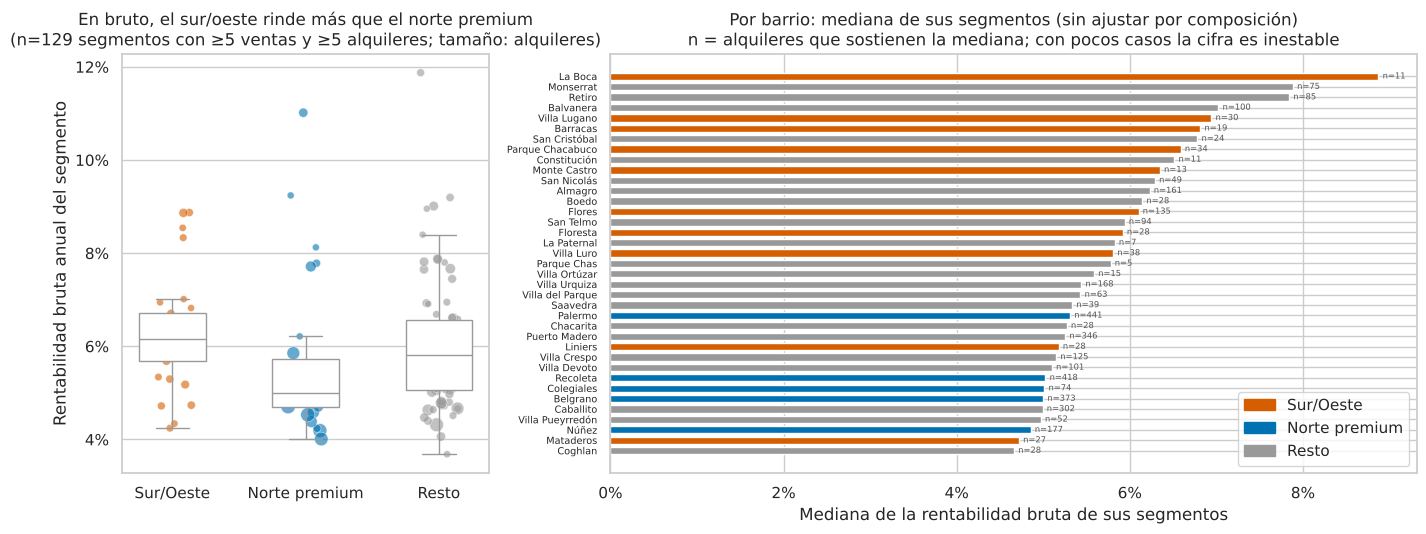

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1, 2.2]})
orden = ['Sur/Oeste', 'Norte premium', 'Resto']
sns.boxplot(data=segmentos, x='Zona', y='Bruta', order=orden, ax=axs[0], color='white', showfliers=False, width=.5)
for i, zona in enumerate(orden):
    s = segmentos.loc[segmentos.Zona.eq(zona)]
    axs[0].scatter(i + np.random.default_rng(SEMILLA).uniform(-.15, .15, len(s)), s.Bruta,
                   s=8 + 2 * np.sqrt(s.n_alquiler) * 4, color=COLORES_ZONA[zona], alpha=.6, edgecolor='white', linewidth=.5)
axs[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
axs[0].set(xlabel='', ylabel='Rentabilidad bruta anual del segmento',
           title=f'En bruto, el sur/oeste rinde más que el norte premium\n(n={len(segmentos)} segmentos con ≥5 ventas y ≥5 alquileres; tamaño: alquileres)')

por_barrio = (segmentos.groupby(['Barrio_Normalizado', 'Zona'])
              .agg(Bruta=('Bruta', 'median'), Alquileres=('n_alquiler', 'sum')).reset_index().sort_values('Bruta'))
axs[1].barh(por_barrio.Barrio_Normalizado, por_barrio.Bruta, color=por_barrio.Zona.map(COLORES_ZONA), height=.7)
axs[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
axs[1].tick_params(axis='y', labelsize=7)
for y_b, (v_b, n_b) in enumerate(zip(por_barrio.Bruta, por_barrio.Alquileres)):
    axs[1].annotate(f'n={n_b}', (v_b, y_b), xytext=(3, 0), textcoords='offset points', va='center', fontsize=6, color='#555555')
axs[1].set(xlabel='Mediana de la rentabilidad bruta de sus segmentos', ylabel='',
           title='Por barrio: mediana de sus segmentos (sin ajustar por composición)\nn = alquileres que sostienen la mediana; con pocos casos la cifra es inestable')
axs[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORES_ZONA.values()],
              labels=list(COLORES_ZONA), loc='lower right', frameon=True)
plt.tight_layout(); plt.show()

**Contraste.** Se estima `log(Bruta) = β·SurOeste + efectos de tipología + ε` sobre los segmentos de ambas zonas; `exp(β) − 1` es la diferencia relativa de rentabilidad entre zonas **para una misma tipología**. La incertidumbre se mide con un **bootstrap jerárquico** de 1.000 réplicas que, en cada réplica, (1) remuestrea barrios dentro de cada zona, porque la variabilidad entre barrios es la que importa para generalizar a la zona, y (2) remuestrea avisos dentro de cada segmento, porque las medianas de segmentos chicos son ruidosas. El p-valor unilateral es la proporción de réplicas con β ≤ 0. Como referencia, se informa también el test de Mann-Whitney, que ignora la composición.

In [7]:
def efecto_zona_h1(seg_h1, ventas_h1, alquileres_h1, columna='Bruta', n_boot=N_BOOTSTRAP, semilla=SEMILLA):
    # Devuelve (beta observado, réplicas bootstrap) del efecto Sur/Oeste sobre log(columna).
    claves = ind.CLAVES_SEGMENTO
    seg_h1 = seg_h1.reset_index(drop=True)
    tipologias = pd.get_dummies(seg_h1.Tipologia).to_numpy(float)
    sur = seg_h1.Zona.eq('Sur/Oeste').to_numpy(float)
    def beta(y, filas):
        x = np.column_stack([sur[filas], tipologias[filas]])
        x = x[:, x.any(axis=0)]
        return np.linalg.lstsq(x, y, rcond=None)[0][0]
    observado = beta(np.log(seg_h1[columna].to_numpy()), np.arange(len(seg_h1)))
    # Precios (o precios por m²) de cada segmento, en el orden de seg_h1.
    def arrays(datos):
        valor = datos.Precio_USD if columna == 'Bruta' else datos.Precio_USD / datos.Superficie_Total_m2
        grupos = valor.groupby([datos[c] for c in claves]).apply(np.asarray)
        return list(grupos.reindex(pd.MultiIndex.from_frame(seg_h1[claves])))
    v, a = arrays(ventas_h1), arrays(alquileres_h1)
    filas_barrio = {b: np.flatnonzero(seg_h1.Barrio_Normalizado.eq(b)) for b in seg_h1.Barrio_Normalizado.unique()}
    barrios_zona = {z: seg_h1.loc[seg_h1.Zona.eq(z), 'Barrio_Normalizado'].unique() for z in seg_h1.Zona.unique()}
    rng = np.random.default_rng(semilla)
    replicas = np.empty(n_boot)
    for b in range(n_boot):
        elegidos = np.concatenate([rng.choice(bs, len(bs)) for bs in barrios_zona.values()])
        filas = np.concatenate([filas_barrio[x] for x in elegidos])
        bruta = np.array([12 * np.median(rng.choice(ai, len(ai))) / np.median(rng.choice(vi, len(vi)))
                          for ai, vi in zip(a, v)])
        replicas[b] = beta(np.log(bruta[filas]), filas)
    return observado, replicas

seg_h1 = segmentos.loc[segmentos.Zona.isin(['Sur/Oeste', 'Norte premium'])]
beta_h1, boot_h1 = efecto_zona_h1(seg_h1, ventas, alquileres)
ic_h1 = np.percentile(boot_h1, [2.5, 97.5])
p_h1 = (np.sum(boot_h1 <= 0) + 1) / (len(boot_h1) + 1)
mw = stats.mannwhitneyu(seg_h1.loc[seg_h1.Zona.eq('Sur/Oeste'), 'Bruta'],
                        seg_h1.loc[seg_h1.Zona.eq('Norte premium'), 'Bruta'], alternative='greater')
ref_norte = seg_h1.loc[seg_h1.Zona.eq('Norte premium'), 'Bruta'].median()
print(f'Efecto Sur/Oeste (misma tipología): {np.expm1(beta_h1):+.1%}  IC95% bootstrap [{np.expm1(ic_h1[0]):+.1%}, '
      f'{np.expm1(ic_h1[1]):+.1%}]  p unilateral={p_h1:.4f}')
print(f'Mann-Whitney sin ajustar (unilateral): U={mw.statistic:.0f}, p={mw.pvalue:.4f}')
print(f'Relevancia práctica: sobre la mediana norte ({ref_norte:.2%}), equivale a '
      f'{ref_norte * np.expm1(beta_h1) * 100:+.2f} puntos porcentuales de rentabilidad bruta anual.')

Efecto Sur/Oeste (misma tipología): +20.6%  IC95% bootstrap [+7.8%, +40.6%]  p unilateral=0.0010
Mann-Whitney sin ajustar (unilateral): U=536, p=0.0038
Relevancia práctica: sobre la mediana norte (5.01%), equivale a +1.03 puntos porcentuales de rentabilidad bruta anual.


**Robustez de H1.** (a) **Definición estricta** de zonas con los barrios que nombra la propuesta (Flores, Parque Avellaneda y Mataderos frente a Palermo, Recoleta y Belgrano). (b) **Rentabilidad por m²**, que neutraliza que el alquiler y la venta de un mismo segmento tengan superficies medianas distintas. (c) **Mínimo de 10 avisos** de cada operación por segmento. (d) **Con avisos repetidos.**

In [8]:
robustez_h1 = {'Principal': (beta_h1, ic_h1, p_h1, len(seg_h1))}

seg_estricta = segmentos.assign(Zona=ind.zona_h1(segmentos.Barrio_Normalizado, estricta=True))
seg_estricta = seg_estricta.loc[seg_estricta.Zona.isin(['Sur/Oeste', 'Norte premium'])]
seg_min10 = seg_h1.loc[seg_h1.n_venta.ge(10) & seg_h1.n_alquiler.ge(10)]
seg_rep = ind.rentabilidad_segmentos(con_repetidos.loc[con_repetidos.venta.eq(1)], con_repetidos.loc[con_repetidos.venta.eq(0)])
seg_rep['Zona'] = ind.zona_h1(seg_rep.Barrio_Normalizado)
seg_rep['Tipologia'] = seg_rep.Tipo_Propiedad + ' ' + seg_rep.Ambientes_Agrupado.astype(str) + ' amb'
seg_rep = seg_rep.loc[seg_rep.Zona.isin(['Sur/Oeste', 'Norte premium'])]
alternativas = {
    'Zonas estrictas (barrios de la propuesta)': (seg_estricta, ventas, alquileres, 'Bruta'),
    'Rentabilidad por m²': (seg_h1, ventas, alquileres, 'Bruta_m2'),
    'Mínimo 10 avisos por operación': (seg_min10, ventas, alquileres, 'Bruta'),
    'Con avisos repetidos': (seg_rep, con_repetidos.loc[con_repetidos.venta.eq(1)],
                             con_repetidos.loc[con_repetidos.venta.eq(0)], 'Bruta')}
for nombre, (s, v, a, col) in alternativas.items():
    b, reps = efecto_zona_h1(s, v, a, columna=col, n_boot=500)
    robustez_h1[nombre] = (b, np.percentile(reps, [2.5, 97.5]), (np.sum(reps <= 0) + 1) / (len(reps) + 1), len(s))
tabla_h1 = pd.DataFrame([(k, len_, np.expm1(b), np.expm1(ic[0]), np.expm1(ic[1]), p)
                         for k, (b, ic, p, len_) in robustez_h1.items()],
                        columns=['Especificación', 'Segmentos', 'Diferencia_Sur_vs_Norte', 'IC95_inf', 'IC95_sup', 'p_unilateral'])
display(tabla_h1.set_index('Especificación'))

registrar('H1', 'Rentabilidad bruta Sur/Oeste > Norte premium (misma tipología)', f'{np.expm1(beta_h1):+.1%}',
          f'[{np.expm1(ic_h1[0]):+.1%}, {np.expm1(ic_h1[1]):+.1%}]', p_h1,
          f'{ref_norte * np.expm1(beta_h1) * 100:+.2f} p.p. sobre una base de {ref_norte:.2%}',
          f'{(tabla_h1.Diferencia_Sur_vs_Norte > 0).sum()}/{len(tabla_h1)}', len(seg_h1),
          'Bootstrap jerárquico (barrios y avisos)', signo_ok=beta_h1 > 0)
lectura(f'Comparando la misma tipología, los segmentos del sur y oeste rinden {np.expm1(beta_h1):+.1%} relativo al '
        f'norte premium (IC95% {np.expm1(ic_h1[0]):+.1%} a {np.expm1(ic_h1[1]):+.1%}). '
        f'El signo se mantiene en {(tabla_h1.Diferencia_Sur_vs_Norte > 0).sum()} de {len(tabla_h1)} especificaciones. '
        'El intervalo del bootstrap jerárquico es amplio porque hay pocos barrios por zona con alquileres suficientes: '
        'la heterogeneidad entre barrios de una misma zona es grande (ver el gráfico por barrio). '
        'La razón de medianas compara avisos distintos; no es el retorno de una unidad concreta.')

,Segmentos,Diferencia_Sur_vs_Norte,IC95_inf,IC95_sup,p_unilateral
Especificación,,,,,
Principal,55,0.2063,0.0784,0.4062,0.0010
Zonas estrictas (barrios de la propuesta),25,0.0735,-0.0911,0.2288,0.1577
Rentabilidad por m²,55,0.2591,0.1170,0.3350,0.0020
Mínimo 10 avisos por operación,36,0.2582,0.0903,0.4997,0.0020
Con avisos repetidos,56,0.2062,0.0637,0.3936,0.0020


**Interpretación.** Comparando la misma tipología, los segmentos del sur y oeste rinden +20.6% relativo al norte premium (IC95% +7.8% a +40.6%). El signo se mantiene en 5 de 5 especificaciones. El intervalo del bootstrap jerárquico es amplio porque hay pocos barrios por zona con alquileres suficientes: la heterogeneidad entre barrios de una misma zona es grande (ver el gráfico por barrio). La razón de medianas compara avisos distintos; no es el retorno de una unidad concreta.

## 4. H3 — Rentabilidad por tamaño de unidad

> **H3:** los monoambientes y 2 ambientes tienen una rentabilidad bruta estimada mayor que las unidades de 3+ ambientes, porque la demanda de alquiler unipersonal y de parejas sostiene alquileres proporcionalmente más altos.

**Diseño pareado.** Comparar todos los segmentos chicos contra todos los grandes mezclaría barrios. Se arma, para cada **barrio × tipo** que tiene segmentos de ambos tamaños, la diferencia `log(Bruta chicas) − log(Bruta grandes)` (promediando 1 y 2 ambientes, y 3 y 4+, cuando ambos existen). El test de **Wilcoxon de rangos con signo** (unilateral) evalúa si esa diferencia tiende a ser positiva sin suponer normalidad. El intervalo de la diferencia mediana se obtiene remuestreando pares.

In [9]:
def diferencias_tamano(seg, columna='Bruta'):
    s = seg.assign(Tamano=np.where(seg.Ambientes_Agrupado.isin(['1', '2']), 'Chica', 'Grande'),
                   log_r=np.log(seg[columna]))
    pares = s.groupby(['Barrio_Normalizado', 'Tipo_Propiedad', 'Tamano']).log_r.mean().unstack().dropna()
    return pares.Chica - pares.Grande

def contraste_h3(dif, semilla=SEMILLA):
    w = stats.wilcoxon(dif, alternative='greater')
    rng = np.random.default_rng(semilla)
    boot = np.array([np.median(rng.choice(dif.to_numpy(), len(dif))) for _ in range(N_BOOTSTRAP)])
    return np.median(dif), np.percentile(boot, [2.5, 97.5]), w.pvalue, len(dif)

dif_h3 = diferencias_tamano(segmentos)
med_h3, ic_h3, p_h3, n_h3 = contraste_h3(dif_h3)
print(f'Pares barrio × tipo: {n_h3} | diferencia mediana chicas − grandes: {np.expm1(med_h3):+.1%} '
      f'IC95% [{np.expm1(ic_h3[0]):+.1%}, {np.expm1(ic_h3[1]):+.1%}] | Wilcoxon p unilateral={p_h3:.4f} | '
      f'pares con chicas más rentables: {(dif_h3 > 0).mean():.0%}')

# Robustez: por m², sin casas, mínimo 10 y una regresión con efectos fijos de barrio y tipo.
seg_m10 = segmentos.loc[segmentos.n_venta.ge(10) & segmentos.n_alquiler.ge(10)]
modelo_h3 = ajustar_cluster('np.log(Bruta) ~ C(Ambientes_Agrupado, Treatment("3")) + C(Barrio_Normalizado) + C(Tipo_Propiedad)',
                            segmentos, ['Bruta'])
filas = [('Principal (pares, Wilcoxon)', n_h3, np.expm1(med_h3), np.expm1(ic_h3[0]), np.expm1(ic_h3[1]), p_h3)]
for nombre, dif in [('Rentabilidad por m²', diferencias_tamano(segmentos, 'Bruta_m2')),
                    ('Solo departamentos', diferencias_tamano(segmentos.loc[segmentos.Tipo_Propiedad.eq('Departamento')])),
                    ('Mínimo 10 avisos por operación', diferencias_tamano(seg_m10))]:
    m, ic, p, n = contraste_h3(dif)
    filas.append((nombre, n, np.expm1(m), np.expm1(ic[0]), np.expm1(ic[1]), p))
tabla_h3 = pd.DataFrame(filas, columns=['Especificación', 'Pares', 'Diferencia_chicas_vs_grandes', 'IC95_inf', 'IC95_sup', 'p_unilateral'])
display(tabla_h3.set_index('Especificación'))
coef_amb = modelo_h3.params.filter(like='Ambientes_Agrupado')
display(pd.DataFrame({'Diferencia vs. 3 ambientes': np.expm1(coef_amb),
                      'p_bilateral': modelo_h3.pvalues[coef_amb.index]}).rename(index=lambda s: s.split('T.')[-1].strip(']')))

Pares barrio × tipo: 28 | diferencia mediana chicas − grandes: -0.6% IC95% [-8.8%, +10.0%] | Wilcoxon p unilateral=0.7165 | pares con chicas más rentables: 50%


,Pares,Diferencia_chicas_vs_grandes,IC95_inf,IC95_sup,p_unilateral
Especificación,,,,,
"Principal (pares, Wilcoxon)",28,-0.0056,-0.0879,0.1000,0.7165
Rentabilidad por m²,28,-0.0462,-0.0924,0.0466,0.9181
Solo departamentos,27,-0.0232,-0.0984,0.1076,0.7502
Mínimo 10 avisos por operación,16,-0.0657,-0.1746,0.1076,0.8628


,Diferencia vs. 3 ambientes,p_bilateral
1,0.0080,0.8652
2,-0.0396,0.2740
4+,0.0297,0.7443


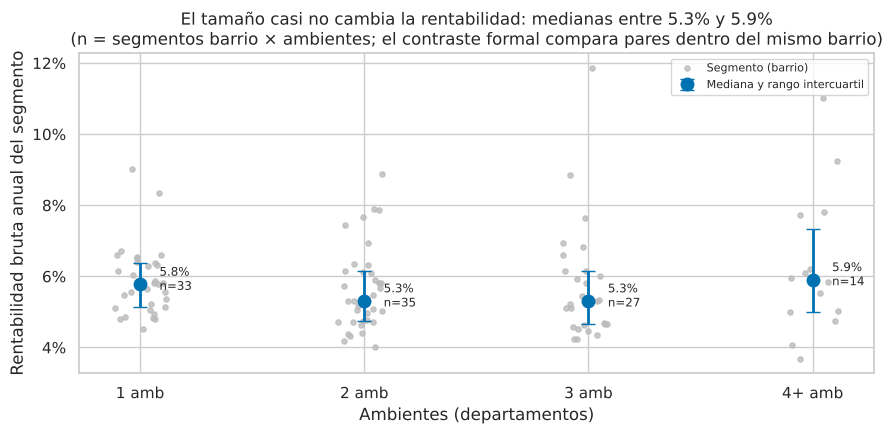

**Interpretación.** En 28 pares barrio × tipo, las unidades chicas rinden en mediana -0.6% relativo a las grandes del mismo barrio (Wilcoxon p=0.7165); en el 50% de los pares la unidad chica rinde más. La versión por m² es la más exigente, porque elimina la diferencia de superficie entre los alquileres y las ventas del segmento. La cobertura de unidades grandes en alquiler es baja: muchos barrios aportan solo el lado chico y quedan fuera del pareo.

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))
perfil = segmentos.loc[segmentos.Tipo_Propiedad.eq('Departamento')].assign(Amb=lambda d: d.Ambientes_Agrupado.astype(str))
orden_amb = ['1', '2', '3', '4+']
resumen_amb = perfil.groupby('Amb').Bruta.agg(n='size', P25=lambda s: s.quantile(.25), Mediana='median',
                                              P75=lambda s: s.quantile(.75)).reindex(orden_amb)
rng_j = np.random.default_rng(SEMILLA)
for i, amb in enumerate(orden_amb):
    s = perfil.loc[perfil.Amb.eq(amb), 'Bruta']
    ax.scatter(i + rng_j.uniform(-.12, .12, len(s)), s, s=14, color='#BBBBBB', alpha=.8, zorder=1,
               label='Segmento (barrio)' if i == 0 else None)
ax.errorbar(range(len(orden_amb)), resumen_amb.Mediana, yerr=[resumen_amb.Mediana - resumen_amb.P25, resumen_amb.P75 - resumen_amb.Mediana],
            fmt='o', color='#0072B2', capsize=5, markersize=9, linewidth=2, zorder=3, label='Mediana y rango intercuartil')
for i, (amb, r) in enumerate(resumen_amb.iterrows()):
    ax.annotate(f'{r.Mediana:.1%}\nn={int(r.n)}', (i, r.Mediana), xytext=(14, -4), textcoords='offset points', fontsize=8.5)
ax.set_xticks(range(len(orden_amb)), [f'{a} amb' for a in orden_amb])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='Ambientes (departamentos)', ylabel='Rentabilidad bruta anual del segmento',
       title=f'El tamaño casi no cambia la rentabilidad: medianas entre {resumen_amb.Mediana.min():.1%} y {resumen_amb.Mediana.max():.1%}\n'
             '(n = segmentos barrio × ambientes; el contraste formal compara pares dentro del mismo barrio)')
ax.legend(loc='upper right', fontsize=8); plt.tight_layout(); plt.show()

registrar('H3', 'Rentabilidad bruta 1–2 amb > 3+ amb (mismo barrio y tipo)', f'{np.expm1(med_h3):+.1%}',
          f'[{np.expm1(ic_h3[0]):+.1%}, {np.expm1(ic_h3[1]):+.1%}]', p_h3,
          f'{np.expm1(med_h3) * segmentos.Bruta.median() * 100:+.2f} p.p. sobre la mediana de {segmentos.Bruta.median():.2%}',
          f'{(tabla_h3.Diferencia_chicas_vs_grandes > 0).sum()}/{len(tabla_h3)}', n_h3, 'Wilcoxon pareado',
          signo_ok=med_h3 > 0)
lectura(f'En {n_h3} pares barrio × tipo, las unidades chicas rinden en mediana {np.expm1(med_h3):+.1%} relativo a las '
        f'grandes del mismo barrio (Wilcoxon p={p_h3:.4f}); en el {(dif_h3 > 0).mean():.0%} de los pares la unidad chica rinde más. '
        'La versión por m² es la más exigente, porque elimina la diferencia de superficie entre los alquileres y las ventas '
        'del segmento. La cobertura de unidades grandes en alquiler es baja: muchos barrios aportan solo el lado chico y '
        'quedan fuera del pareo.')

## 5. H2 — Amenities y cochera en venta frente a alquiler

> **H2:** la presencia de amenities y cochera incrementa el precio de venta por m² más de lo que incrementa el alquiler por m², lo que reduce la rentabilidad bruta relativa de las unidades premium dentro de un mismo barrio.

**Modelo.** Se apilan ventas y alquileres y se estima `log(USD/m²)` con **todas** las pendientes interactuadas con la operación, más efectos fijos de barrio × operación:

`log(USD/m²) = venta × (cochera + amenities + log(superficie) + ambientes + antigüedad + tipo) + barrio × operación`

El coeficiente `venta:cochera` es exactamente la **diferencia entre la prima de la cochera en venta y en alquiler**. H2 predice que es positivo. Su efecto sobre la rentabilidad es `exp(−β) − 1`: si la cochera encarece la venta más que el alquiler, la rentabilidad cae. *Amenities de edificio* = cantidad de pileta, gimnasio, SUM, laundry y seguridad (0–5). Recordatorio: un amenity en 0 significa *no informado*, no necesariamente ausente.

In [11]:
COLS_H2 = ['log_m2', 'cochera', 'amenities_edificio', 'log_superficie', 'Ambientes_Agrupado', 'Antiguedad_limpia',
           'Tipo_Propiedad', 'Barrio_Normalizado', 'Tipo_Operacion']
F_H2 = ('log_m2 ~ venta * ({x} + log_superficie + C(Ambientes_Agrupado) + Antiguedad_limpia{tipo}) '
        '+ C(Barrio_Normalizado):C(Tipo_Operacion)')
def modelo_h2(datos, x='cochera + amenities_edificio', tipo=' + C(Tipo_Propiedad)'):
    return ajustar_cluster(F_H2.format(x=x, tipo=tipo), datos, COLS_H2)

sin_extremos = lambda d: d.loc[d.Flag_Precio_m2_Muy_Bajo.eq(0) & d.Flag_Precio_m2_Muy_Alto.eq(0)]
h2 = {'Principal': modelo_h2(base),
      'Solo departamentos': modelo_h2(base.loc[base.Tipo_Propiedad.eq('Departamento')], tipo=''),
      'Sin precios fuera de contexto': modelo_h2(sin_extremos(base)),
      'Con avisos repetidos': modelo_h2(con_repetidos)}
base_amen = base.assign(amenities_edificio=base.amenities_edificio.ge(2).astype(int))
h2['Amenities binario (≥2)'] = modelo_h2(base_amen)

primas = []
for termino, etiqueta in [('cochera', 'Cochera'), ('amenities_edificio', 'Amenities (+1)')]:
    m = h2['Principal']
    alq, dif = contraste(m, termino, 0), contraste(m, f'venta:{termino}', +1)
    primas.append({'Atributo': etiqueta, 'Prima_alquiler': np.expm1(alq['beta']),
                   'Prima_venta': np.expm1(alq['beta'] + dif['beta']), 'Diferencia_beta (venta − alquiler)': dif['beta'],
                   'IC95_inf': dif['ic_inf'], 'IC95_sup': dif['ic_sup'], 'p_unilateral_H2': dif['p_unilateral'],
                   'Efecto_en_rentabilidad': np.expm1(-dif['beta'])})
primas = pd.DataFrame(primas).set_index('Atributo')
display(primas)
rob_cochera = tabla_robustez(h2, 'venta:cochera', +1)
rob_amen = tabla_robustez(h2, 'venta:amenities_edificio', +1)
display(pd.concat({'venta:cochera': rob_cochera[['beta', 'ic_inf', 'ic_sup', 'p_unilateral', 'n']],
                   'venta:amenities': rob_amen[['beta', 'ic_inf', 'ic_sup', 'p_unilateral', 'n']]}, axis=1))

,Prima_alquiler,Prima_venta,Diferencia_beta (venta − alquiler),IC95_inf,IC95_sup,p_unilateral_H2,Efecto_en_rentabilidad
Atributo,,,,,,,
Cochera,0.1766,0.1423,-0.0296,-0.0755,0.0164,0.8989,0.0300
Amenities (+1),0.0631,0.0646,0.0015,-0.0126,0.0156,0.4161,-0.0015


venta:cochera                                    venta:amenities                                   
                                       beta  ic_inf ic_sup p_unilateral      n            beta  ic_inf ic_sup p_unilateral      n
Especificación                                                                                                                   
Principal                           -0.0296 -0.0755 0.0164       0.8989  48255          0.0015 -0.0126 0.0156       0.4161  48255
Solo departamentos                  -0.0202 -0.0676 0.0273       0.8014  39871         -0.0012 -0.0155 0.0132       0.5636  39871
Sin precios fuera de contexto       -0.0302 -0.0700 0.0097       0.9329  47837          0.0011 -0.0125 0.0147       0.4360  47837
Con avisos repetidos                -0.0221 -0.0723 0.0282       0.8095  50449          0.0030 -0.0107 0.0168       0.3297  50449
Amenities binario (≥2)              -0.0338 -0.0854 0.0178       0.9031  48255          0.0027 -0.0283 0.0337       0.4314  48255

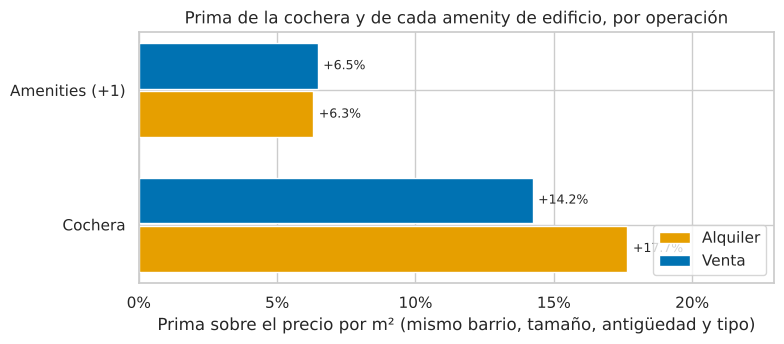

**Interpretación.** La cochera se asocia con una prima de +14.2% en el USD/m² de venta y de +17.7% en el de alquiler. H2 esperaba la prima mayor en venta; la diferencia estimada es -0.030 (p unilateral=0.899). Cada amenity de edificio informado agrega +6.5% en venta y +6.3% en alquiler: primas casi idénticas, así que, con estos datos, equipar la unidad no cambia sistemáticamente la rentabilidad relativa. Los atributos sí elevan el capital necesario y el alquiler en proporciones similares.

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(primas))
for k, (op, col) in enumerate([('Alquiler', 'Prima_alquiler'), ('Venta', 'Prima_venta')]):
    ax.barh(y + (k - .5) * .36, primas[col], height=.34, color=COLORES_OPERACION[op], label=op)
    for yi, v in zip(y, primas[col]):
        ax.annotate(f'{v:+.1%}', (v, yi + (k - .5) * .36), xytext=(4, 0), textcoords='offset points', va='center', fontsize=9)
ax.set_yticks(y, primas.index)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set(xlabel='Prima sobre el precio por m² (mismo barrio, tamaño, antigüedad y tipo)',
       title='Prima de la cochera y de cada amenity de edificio, por operación')
ax.legend(loc='lower right'); ax.set_xlim(0, primas[['Prima_alquiler', 'Prima_venta']].max().max() * 1.3)
plt.tight_layout(); plt.show()

for termino, nombre, rob in [('cochera', 'H2a', rob_cochera), ('amenities_edificio', 'H2b', rob_amen)]:
    r = contraste(h2['Principal'], f'venta:{termino}', +1)
    registrar(nombre, f'Prima de {"la cochera" if termino == "cochera" else "los amenities"} mayor en venta que en alquiler',
              f'{r["beta"]:+.3f}', f'[{r["ic_inf"]:+.3f}, {r["ic_sup"]:+.3f}]', r['p_unilateral'],
              f'{np.expm1(-r["beta"]):+.1%} en la rentabilidad bruta de la unidad', f'{rob.Signo_esperado.sum()}/{len(rob)}',
              r['n'], 'Diferencia de coeficientes; errores por barrio', signo_ok=r['beta'] > 0)
c = primas.loc['Cochera']
lectura(f'La cochera se asocia con una prima de {c.Prima_venta:+.1%} en el USD/m² de venta y de {c.Prima_alquiler:+.1%} '
        f'en el de alquiler. H2 esperaba la prima mayor en venta; la diferencia estimada es {c["Diferencia_beta (venta − alquiler)"]:+.3f} '
        f'(p unilateral={c.p_unilateral_H2:.3f}). Cada amenity de edificio informado agrega '
        f'{primas.loc["Amenities (+1)"].Prima_venta:+.1%} en venta y {primas.loc["Amenities (+1)"].Prima_alquiler:+.1%} en alquiler: '
        'primas casi idénticas, así que, con estos datos, equipar la unidad no cambia sistemáticamente la rentabilidad '
        'relativa. Los atributos sí elevan el capital necesario y el alquiler en proporciones similares.')

## 6. H4, H4.5, H4b, H5 y H8 — Entorno urbano y precio de venta

> **H4:** la distancia a la estación de subte más cercana correlaciona negativamente con el USD/m² de venta, controlando por barrio.
> **H4.5:** la cantidad de estaciones de subte a 500 m correlaciona positivamente con el USD/m² de venta, controlando por barrio.
> **H4b:** la accesibilidad a colectivos (paradas a 500 m) se relaciona con diferencias de precio dentro de una misma zona.
> **H5:** la cantidad de delitos del entorno correlaciona negativamente con el USD/m² de venta, controlando por barrio y amenities.
> **H8:** la distancia al centro de salud más cercano correlaciona negativamente con el USD/m² de venta, controlando por barrio.

**Modelo hedónico conjunto** sobre las ventas, con efectos fijos de barrio: la identificación viene de comparar avisos **dentro del mismo barrio**. Controles: log(superficie), ambientes, antigüedad, tipo, confort informado, cochera y amenities de edificio. Las variables de entorno entran juntas, porque están correlacionadas entre sí (cerca del subte suele haber más colectivos y más delitos registrados), y por separado como robustez.

Notas de medición: delitos es un **conteo 2023–2025 en 1.000 m**, no una tasa por habitante (la propuesta preveía 500 m); las distancias son en línea recta. H4b no tenía dirección en la propuesta: se contrasta bilateralmente.

In [13]:
CONTROLES = ('log_superficie + C(Ambientes_Agrupado) + Antiguedad_limpia + C(Tipo_Propiedad) '
             '+ Tasa_Confort_Amenities + cochera + amenities_edificio')
ENTORNO = ['log_subte', 'subte_500m', 'log_colectivos', 'log_delitos', 'log_hospital', 'log_verde']
COLS_ENT = ['log_m2', 'log_superficie', 'Ambientes_Agrupado', 'Antiguedad_limpia', 'Tipo_Propiedad',
            'Tasa_Confort_Amenities', 'cochera', 'amenities_edificio', 'Barrio_Normalizado'] + ENTORNO
def modelo_entorno(datos, terminos=ENTORNO, efectos='C(Barrio_Normalizado)', controles=CONTROLES):
    return ajustar_cluster(f'log_m2 ~ {" + ".join(terminos)} + {controles} + {efectos}', datos, COLS_ENT)

v_rep = con_repetidos.loc[con_repetidos.venta.eq(1)]
deptos = ventas.loc[ventas.Tipo_Propiedad.eq('Departamento')]
ent = {'Principal (conjunto, FE barrio)': modelo_entorno(ventas),
       'Sin efectos de barrio (FE comuna)': modelo_entorno(ventas, efectos='C(Comuna)'),
       'Solo departamentos': modelo_entorno(deptos, controles=CONTROLES.replace(' + C(Tipo_Propiedad)', '')),
       'Sin precios fuera de contexto': modelo_entorno(sin_extremos(ventas)),
       'Con avisos repetidos': modelo_entorno(v_rep)}
HIP_ENT = {'H4': ('log_subte', -1, 'Distancia al subte'), 'H4.5': ('subte_500m', +1, 'Estaciones de subte a 500 m'),
           'H4b': ('log_colectivos', 0, 'Paradas de colectivo a 500 m'), 'H5': ('log_delitos', -1, 'Delitos a 1.000 m'),
           'H8': ('log_hospital', -1, 'Distancia al hospital')}
robustez_ent = {}
for h, (termino, signo, _) in HIP_ENT.items():
    especificaciones = dict(ent)
    especificaciones['Variable sola (FE barrio)'] = modelo_entorno(ventas, terminos=[termino])
    robustez_ent[h] = tabla_robustez(especificaciones, termino, signo)
display(pd.concat({h: t[['beta', 'ic_inf', 'ic_sup', 'p_unilateral', 'n']] for h, t in robustez_ent.items()}).round(4))

beta  ic_inf  ic_sup  p_unilateral      n
     Especificación                                                                
H4   Principal (conjunto, FE barrio)   -0.0093 -0.0262  0.0076        0.1363  44119
     Sin efectos de barrio (FE comuna) -0.0128 -0.0374  0.0119        0.1511  44119
     Solo departamentos                -0.0078 -0.0236  0.0080        0.1616  36088
     Sin precios fuera de contexto     -0.0073 -0.0236  0.0090        0.1857  43747
     Con avisos repetidos              -0.0092 -0.0264  0.0079        0.1419  46065
     Variable sola (FE barrio)          0.0070 -0.0158  0.0297        0.7291  44119
H4.5 Principal (conjunto, FE barrio)   -0.0071 -0.0244  0.0101        0.7957  44119
     Sin efectos de barrio (FE comuna) -0.0270 -0.0528 -0.0012        0.9798  44119
     Solo departamentos                -0.0049 -0.0209  0.0112        0.7271  36088
     Sin precios fuera de contexto     -0.0061 -0.0240  0.0118        0.7525  43747
     Con avisos repetidos              -0.0075 -0.0260  0.0110        0.7916  46065
     Variable sola (FE barrio)         -0.0117 -0.0297  0.0064        0.9001  44119
H4b  Principal (conjunto, FE barrio)   -0.0640 -0.1050 -0.0230        0.0029  44119
     Sin efectos de barrio (FE comuna) -0.0935 -0.1630 -0.0240        0.0095  44119
     Solo departamentos                -0.0680 -0.1112 -0.0248        0.0027  36088
     Sin precios fuera de contexto     -0.0569 -0.0971 -0.0167        0.0065  43747
     Con avisos repetidos              -0.0642 -0.1063 -0.0222        0.0035  46065
     Variable sola (FE barrio)         -0.0604 -0.1070 -0.0138        0.0122  44119
H5   Principal (conjunto, FE barrio)    0.0045 -0.0389  0.0480        0.5828  44119
     Sin efectos de barrio (FE comuna) -0.0281 -0.0945  0.0383        0.1996  44119
     Solo departamentos                -0.0087 -0.0557  0.0383        0.3556  36088
     Sin precios fuera de contexto      0.0068 -0.0341  0.0476        0.6298  43747
     Con avisos repetidos               0.0022 -0.0422  0.0467        0.5402  46065
     Variable sola (FE barrio)         -0.0241 -0.0768  0.0286        0.1811  44119
H8   Principal (conjunto, FE barrio)   -0.0142 -0.0451  0.0167        0.1805  44119
     Sin efectos de barrio (FE comuna)  0.0043 -0.0352  0.0439        0.5867  44119
     Solo departamentos                -0.0028 -0.0291  0.0236        0.4159  36088
     Sin precios fuera de contexto     -0.0120 -0.0409  0.0168        0.2031  43747
     Con avisos repetidos              -0.0155 -0.0468  0.0159        0.1630  46065
     Variable sola (FE barrio)         -0.0158 -0.0441  0.0124        0.1325  44119

**Magnitud.** Un coeficiente en logaritmos es difícil de leer. Para cada variable se calcula el cambio esperado en el USD/m² al pasar del **percentil 25 al 75** de esa variable dentro de las ventas (un cambio típico entre dos avisos), y su equivalente en USD sobre la venta mediana.

,Variable,Efecto_P25_a_P75,IC95_inf,IC95_sup,USD_sobre_venta_mediana,p_unilateral,Especificaciones_con_signo_esperado
Hipótesis,,,,,,,
H4,Distancia al subte,-0.0148,-0.0410,0.0122,"-2,147.1465",0.1363,5/6
H4.5,Estaciones de subte a 500 m,-0.0071,-0.0241,0.0101,"-1,033.1856",0.7957,0/6
H4b,Paradas de colectivo a 500 m,-0.0434,-0.0702,-0.0158,"-6,306.1557",0.0029,6/6
H5,Delitos a 1.000 m,0.0042,-0.0352,0.0451,608.2055,0.5828,3/6
H8,Distancia al hospital,-0.0115,-0.0360,0.0137,"-1,666.9578",0.1805,5/6


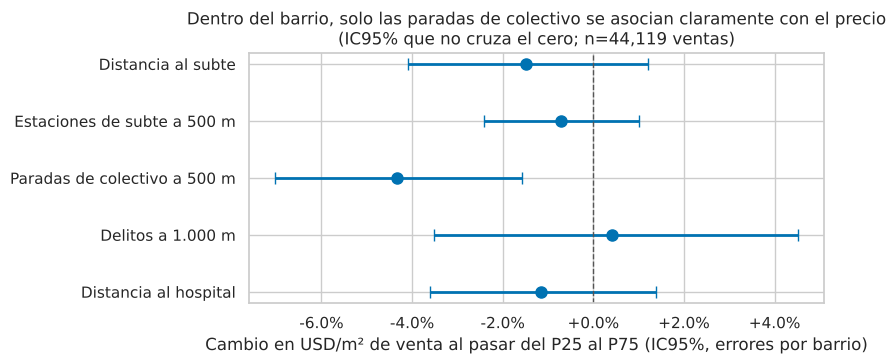

In [14]:
precio_mediano = ventas.Precio_USD.median()
magnitudes = []
for h, (termino, signo, etiqueta) in HIP_ENT.items():
    r = contraste(ent['Principal (conjunto, FE barrio)'], termino, signo)
    p25, p75 = ventas[termino].quantile([.25, .75])
    efecto = np.expm1(r['beta'] * (p75 - p25))
    efecto_ic = np.expm1(np.array([r['ic_inf'], r['ic_sup']]) * (p75 - p25))
    rob = robustez_ent[h]
    magnitudes.append({'Hipótesis': h, 'Variable': etiqueta, 'Efecto_P25_a_P75': efecto,
                       'IC95_inf': efecto_ic.min(), 'IC95_sup': efecto_ic.max(), 'USD_sobre_venta_mediana': efecto * precio_mediano,
                       'p_unilateral': r['p_unilateral'], 'Especificaciones_con_signo_esperado': f'{rob.Signo_esperado.sum()}/{len(rob)}'})
    registrar(h, f'{etiqueta} → USD/m² de venta ({"bilateral" if signo == 0 else ("−" if signo < 0 else "+")})',
              f'{r["beta"]:+.4f}', f'[{r["ic_inf"]:+.4f}, {r["ic_sup"]:+.4f}]', r['p_unilateral'],
              f'{efecto:+.1%} de P25 a P75 ({efecto * precio_mediano:+,.0f} USD)', f'{rob.Signo_esperado.sum()}/{len(rob)}',
              r['n'], 'FE barrio; errores por barrio', signo_ok=True if signo == 0 else bool(np.sign(r['beta']) == signo))
magnitudes = pd.DataFrame(magnitudes).set_index('Hipótesis')
display(magnitudes)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
m = magnitudes.iloc[::-1]
ax.errorbar(m.Efecto_P25_a_P75, m.Variable, xerr=[m.Efecto_P25_a_P75 - m.IC95_inf, m.IC95_sup - m.Efecto_P25_a_P75],
            fmt='o', color='#0072B2', ecolor='#0072B2', capsize=4, markersize=8, linewidth=2)
ax.axvline(0, color='#555555', linestyle='--', linewidth=1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:+.1%}'))
ax.set(xlabel='Cambio en USD/m² de venta al pasar del P25 al P75 (IC95%, errores por barrio)', ylabel='',
       title=f'Dentro del barrio, solo las paradas de colectivo se asocian claramente con el precio\n'
             f'(IC95% que no cruza el cero; n={int(ent["Principal (conjunto, FE barrio)"].nobs):,} ventas)')
plt.tight_layout(); plt.show()

In [15]:
mg = magnitudes
lectura('Dentro de un mismo barrio, las variables de entorno explican diferencias de precio **chicas**: ningún paso del '
        f'P25 al P75 mueve el USD/m² más de {mg.Efecto_P25_a_P75.abs().max():.1%}. '
        f'La distancia al subte (H4) tiene un efecto de {mg.loc["H4"].Efecto_P25_a_P75:+.1%} y las estaciones a 500 m (H4.5) '
        f'de {mg.loc["H4.5"].Efecto_P25_a_P75:+.1%}. Los colectivos (H4b) muestran {mg.loc["H4b"].Efecto_P25_a_P75:+.1%}: más paradas se '
        'asocian con **menor** precio, compatible con que las paradas se concentran sobre avenidas ruidosas y de mayor tránsito. '
        f'Los delitos (H5) dan {mg.loc["H5"].Efecto_P25_a_P75:+.1%}. '
        'La especificación sin efectos de barrio muestra cuánto absorbe el barrio: entre barrios estas variables pesan mucho más, '
        'pero esa comparación mezcla todo lo que distingue a un barrio de otro. Ninguno de estos coeficientes es causal: '
        'la ubicación publicada es aproximada y el conteo de delitos refleja tanto riesgo como circulación de personas.')

**Interpretación.** Dentro de un mismo barrio, las variables de entorno explican diferencias de precio **chicas**: ningún paso del P25 al P75 mueve el USD/m² más de 4.3%. La distancia al subte (H4) tiene un efecto de -1.5% y las estaciones a 500 m (H4.5) de -0.7%. Los colectivos (H4b) muestran -4.3%: más paradas se asocian con **menor** precio, compatible con que las paradas se concentran sobre avenidas ruidosas y de mayor tránsito. Los delitos (H5) dan +0.4%. La especificación sin efectos de barrio muestra cuánto absorbe el barrio: entre barrios estas variables pesan mucho más, pero esa comparación mezcla todo lo que distingue a un barrio de otro. Ninguno de estos coeficientes es causal: la ubicación publicada es aproximada y el conteo de delitos refleja tanto riesgo como circulación de personas.

## 7. H7 — Espacios verdes y unidades familiares (reformulada)

> **H7 original:** la densidad de establecimientos educativos y de espacios verdes correlaciona positivamente con el alquiler por m² de las unidades de 3+ ambientes en mayor medida que en las de 1–2 ambientes.

**Reformulación.** El dataset de establecimientos educativos no llegó a integrarse, así que la componente educativa **no puede evaluarse**. Se contrasta la parte verificable:

> **H7 (reformulada):** la superficie de espacios verdes a 1.000 m se asocia con el USD/m² de alquiler **más** en las unidades de 3+ ambientes (proxy de perfil familiar) que en las de 1–2 ambientes.

El contraste es la interacción `log_verde × familiar` en un modelo de alquileres con efectos fijos de barrio (H7 se formuló sobre alquiler). Robustez: otras medidas de verde (cantidad de espacios, distancia al más cercano, con el signo invertido) y el mismo modelo sobre ventas. La muestra de alquileres es chica: el poder estadístico es limitado.

In [16]:
CONT_H7 = ('log_subte + log_colectivos + log_delitos + log_superficie + Antiguedad_limpia + C(Tipo_Propiedad) '
           '+ Tasa_Confort_Amenities + cochera + C(Barrio_Normalizado)')
COLS_H7 = ['log_m2', 'familiar', 'log_subte', 'log_colectivos', 'log_delitos', 'log_superficie', 'Antiguedad_limpia',
           'Tipo_Propiedad', 'Tasa_Confort_Amenities', 'cochera', 'Barrio_Normalizado']
def modelo_h7(datos, verde='log_verde'):
    return ajustar_cluster(f'log_m2 ~ {verde} * familiar + {CONT_H7}', datos, COLS_H7 + [verde])

a_rep = con_repetidos.loc[con_repetidos.venta.eq(0)]
h7 = {'Principal (alquiler, superficie verde)': (modelo_h7(alquileres), 'log_verde:familiar', +1),
      'Alquiler: cantidad de espacios verdes': (modelo_h7(alquileres, 'espacios_verdes'), 'espacios_verdes:familiar', +1),
      'Alquiler: distancia al verde (signo −)': (modelo_h7(alquileres, 'log_dist_verde'), 'log_dist_verde:familiar', -1),
      'Alquiler sin precios fuera de contexto': (modelo_h7(sin_extremos(alquileres)), 'log_verde:familiar', +1),
      'Alquiler con avisos repetidos': (modelo_h7(a_rep), 'log_verde:familiar', +1),
      'Venta (complemento)': (modelo_h7(ventas), 'log_verde:familiar', +1)}
tabla_h7 = pd.DataFrame({k: {**contraste(m, t, s), 'Signo_esperado': np.sign(contraste(m, t, s)['beta']) == s}
                         for k, (m, t, s) in h7.items()}).T
display(tabla_h7[['beta', 'ic_inf', 'ic_sup', 'p_unilateral', 'n', 'Signo_esperado']])

m7 = h7['Principal (alquiler, superficie verde)'][0]
r7 = contraste(m7, 'log_verde:familiar', +1)
p25, p75 = alquileres.log_verde.quantile([.25, .75])
pend_chica, pend_flia = m7.params['log_verde'], m7.params['log_verde'] + m7.params['log_verde:familiar']
registrar('H7 (reformulada)', 'Asociación verde–alquiler/m² mayor en 3+ amb que en 1–2 amb', f'{r7["beta"]:+.4f}',
          f'[{r7["ic_inf"]:+.4f}, {r7["ic_sup"]:+.4f}]', r7['p_unilateral'],
          f'P25→P75 de verde: {np.expm1(pend_chica * (p75 - p25)):+.1%} en 1–2 amb vs {np.expm1(pend_flia * (p75 - p25)):+.1%} en 3+ amb',
          f'{tabla_h7.Signo_esperado.astype(int).sum()}/{len(tabla_h7)}', r7['n'], 'Sin componente educativa (dato no integrado)',
          signo_ok=r7['beta'] > 0)
lectura(f'Más verde a 1.000 m se asocia con alquileres más altos por m²: del P25 al P75 de superficie verde, '
        f'{np.expm1(pend_chica * (p75 - p25)):+.1%} en unidades de 1–2 ambientes y {np.expm1(pend_flia * (p75 - p25)):+.1%} '
        f'en 3+ ambientes. La interacción que pide H7 es {r7["beta"]:+.4f} (p unilateral={r7["p_unilateral"]:.3f}): '
        'la asociación **no es mayor** en las unidades familiares. Esto coincide con la falta de robustez que ya había '
        'encontrado el notebook 04. El verde se valora, pero no aparece como un atributo específico del segmento familiar.')

,beta,ic_inf,ic_sup,p_unilateral,n,Signo_esperado
"Principal (alquiler, superficie verde)",-0.0098,-0.0333,0.0136,0.7982,4042,False
Alquiler: cantidad de espacios verdes,0.0004,-0.0057,0.0064,0.4503,4042,True
Alquiler: distancia al verde (signo −),0.0097,-0.0260,0.0454,0.7067,4042,False
Alquiler sin precios fuera de contexto,-0.0125,-0.0348,0.0098,0.8678,3998,False
Alquiler con avisos repetidos,-0.0097,-0.0352,0.0158,0.7762,4285,False
Venta (complemento),0.0017,-0.0095,0.0130,0.3789,44119,True


**Interpretación.** Más verde a 1.000 m se asocia con alquileres más altos por m²: del P25 al P75 de superficie verde, +5.5% en unidades de 1–2 ambientes y +3.8% en 3+ ambientes. La interacción que pide H7 es -0.0098 (p unilateral=0.798): la asociación **no es mayor** en las unidades familiares. Esto coincide con la falta de robustez que ya había encontrado el notebook 04. El verde se valora, pero no aparece como un atributo específico del segmento familiar.

,Cuartil_verde,Tamaño,n,P25,Mediana,P75
0,Q1 (menos verde),1–2 ambientes,720,10.2400,11.8400,13.6500
1,Q1 (menos verde),3+ ambientes,312,8.6300,10.4700,12.9400
2,Q2,1–2 ambientes,691,10.3600,11.8400,13.8700
3,Q2,3+ ambientes,324,9.1700,11.4500,14.7700
4,Q3,1–2 ambientes,658,10.5700,12.5500,14.7900
5,Q3,3+ ambientes,357,9.5500,11.5000,15.6900
6,Q4 (más verde),1–2 ambientes,606,12.3400,16.2700,25.6300
7,Q4 (más verde),3+ ambientes,415,11.3000,16.5100,23.0300


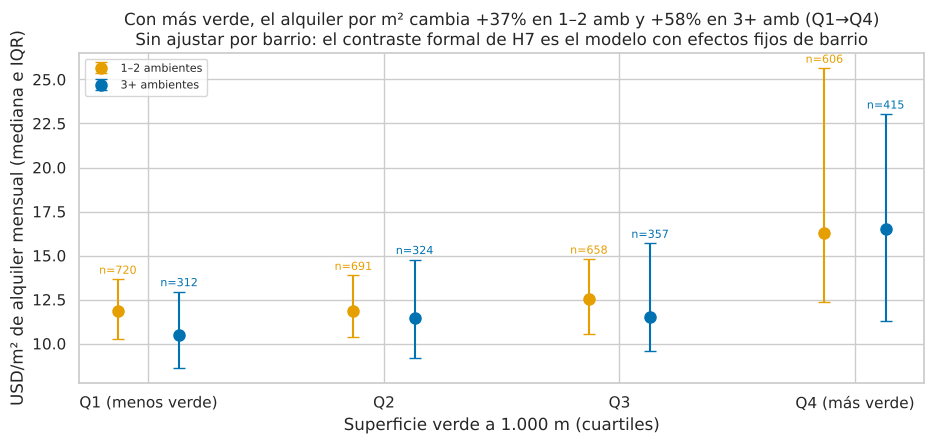

**Interpretación.** Cada punto es la mediana del alquiler por m² del tramo y las barras van del percentil 25 al 75; n es la cantidad de alquileres del tramo. Los rangos de los dos tamaños se superponen en todos los cuartiles. Sin ajustar, el alquiler de las unidades de 3+ ambientes sube más con el verde (+58% contra +37%), y casi todo el salto ocurre en el cuartil de más verde. Ese cuartil concentra barrios caros con parques grandes, así que la comparación mezcla verde con barrio. Dentro del mismo barrio (modelo de la celda anterior) la diferencia entre tamaños desaparece: por eso H7 no se sostiene. El gráfico muestra por qué la lectura sin ajustar sería engañosa.

In [17]:
# H7 en gráfico: mediana e IQR del alquiler por m² por cuartil de verde y tamaño. Puntos separados, sin líneas:
# los cuartiles mezclan barrios y tipos, y unirlos sugeriría una tendencia más firme que la evidencia.
a7 = alquileres.dropna(subset=['log_verde']).assign(USD_m2=lambda d: d.Precio_USD / d.Superficie_Total_m2)
a7['Cuartil_verde'] = pd.qcut(a7.Superficie_Verde_1000m_m2, 4, labels=['Q1 (menos verde)', 'Q2', 'Q3', 'Q4 (más verde)'])
a7['Tamaño'] = np.where(a7.familiar.eq(1), '3+ ambientes', '1–2 ambientes')
tab7 = a7.groupby(['Cuartil_verde', 'Tamaño'], observed=True).USD_m2.agg(
    n='size', P25=lambda s: s.quantile(.25), Mediana='median', P75=lambda s: s.quantile(.75)).reset_index()
display(tab7.round(2))
med7 = tab7.pivot(index='Cuartil_verde', columns='Tamaño', values='Mediana')
cambio7 = med7.iloc[-1] / med7.iloc[0] - 1

fig, ax = plt.subplots(figsize=(9.5, 4.6))
colores7 = {'1–2 ambientes': '#E69F00', '3+ ambientes': '#0072B2'}
for k, (tam, g) in enumerate(tab7.groupby('Tamaño')):
    xs = g.Cuartil_verde.cat.codes.to_numpy() + (k - .5) * .26
    ax.errorbar(xs, g.Mediana, yerr=[g.Mediana - g.P25, g.P75 - g.Mediana], fmt='o', color=colores7[tam],
                capsize=4, markersize=8, linewidth=1.5, label=tam)
    for xi, (_, r) in zip(xs, g.iterrows()):
        ax.annotate(f'n={r.n}', (xi, r.P75), xytext=(0, 4), textcoords='offset points', ha='center', fontsize=8, color=colores7[tam])
ax.set_xticks(range(4), a7.Cuartil_verde.cat.categories)
ax.set(xlabel='Superficie verde a 1.000 m (cuartiles)', ylabel='USD/m² de alquiler mensual (mediana e IQR)',
       title=f'Con más verde, el alquiler por m² cambia {cambio7["1–2 ambientes"]:+.0%} en 1–2 amb y {cambio7["3+ ambientes"]:+.0%} en 3+ amb (Q1→Q4)\n'
             'Sin ajustar por barrio: el contraste formal de H7 es el modelo con efectos fijos de barrio')
ax.legend(loc='upper left', fontsize=8); plt.tight_layout(); plt.show()
lectura('Cada punto es la mediana del alquiler por m² del tramo y las barras van del percentil 25 al 75; n es la cantidad '
        'de alquileres del tramo. Los rangos de los dos tamaños se superponen en todos los cuartiles. '
        f'Sin ajustar, el alquiler de las unidades de 3+ ambientes sube más con el verde ({cambio7["3+ ambientes"]:+.0%} contra '
        f'{cambio7["1–2 ambientes"]:+.0%}), y casi todo el salto ocurre en el cuartil de más verde. Ese cuartil concentra barrios '
        'caros con parques grandes, así que la comparación mezcla verde con barrio. Dentro del mismo barrio (modelo de la celda anterior) '
        'la diferencia entre tamaños desaparece: por eso H7 no se sostiene. El gráfico muestra por qué la lectura sin ajustar sería engañosa.')

## 8. Modelo de precio de referencia y validación fuera de muestra

**Pregunta predictiva:** ¿se puede estimar el precio de un aviso a partir de sus características y su entorno, mejor que con la regla de comparables que usa el `Indice_Subvaluacion` original? Es una **estimación actual** (el valor de mercado publicado hoy de un aviso nuevo), no un pronóstico temporal.

**Estimadores** (`src/modelos.py`), todos sobre log(precio USD):
- **Baseline:** mediana de USD/m² de comparables × superficie, en cascada barrio × tipo × ambientes → barrio × tipo → barrio (mínimo 8). Es la referencia razonable que exige la consigna: reproduce la lógica del KPI original.
- **Ridge:** regresión hedónica lineal con atributos, amenities, entorno, barrio, tipo y estado.
- **Gradient boosting (HGB):** las mismas variables más latitud y longitud, con no linealidades e interacciones.

**Validación:** 5 pliegues **agrupados por inmueble**: los avisos que el notebook 02 marcó como el mismo inmueble caen en el mismo pliegue, para que el modelo nunca se evalúe contra una copia de un aviso que vio al entrenar. Cada aviso recibe una predicción de un modelo que no lo vio. Métricas: MdAPE (error porcentual absoluto mediano), proporción de avisos dentro de ±10% y ±20%, y R² en log.

In [18]:
datos_modelo = {op: mod.preparar_features(base.loc[base.Tipo_Operacion.eq(op)]) for op in ['Venta', 'Alquiler']}
cv = {op: mod.validacion_cruzada(d) for op, d in datos_modelo.items()}
metricas_cv = pd.DataFrame([{'Operación': op, 'Modelo': nombre, 'n': len(res), **mod.metricas(res.y, res[nombre])}
                            for op, res in cv.items() for nombre in ['baseline', 'ridge', 'hgb']]).set_index(['Operación', 'Modelo'])
display(metricas_cv)

# Variabilidad entre pliegues: el ranking de modelos no debe depender de un pliegue en particular.
por_pliegue = pd.DataFrame([{'Operación': op, 'Pliegue': k, **{nombre: mod.metricas(g.y, g[nombre])['MdAPE_%']
                            for nombre in ['baseline', 'ridge', 'hgb']}} for op, res in cv.items() for k, g in res.groupby('pliegue')])
display(por_pliegue.groupby('Operación')[['baseline', 'ridge', 'hgb']].agg(['mean', 'min', 'max']).round(2))

n  MAE_log  MdAPE_%  Dentro_10%  Dentro_20%  R2_log
Operación Modelo                                                           
Venta     baseline  45825   0.2195  16.9355     31.4479     56.8882  0.8260
          ridge     45825   0.1730  13.4379     38.7278     67.5723  0.8898
          hgb       45825   0.1293   9.6971     51.2362     79.6748  0.9351
Alquiler  baseline   4099   0.2259  16.9811     32.0566     57.5506  0.7967
          ridge      4099   0.1799  13.4230     39.4486     67.4799  0.8621
          hgb        4099   0.1668  12.1452     42.9129     71.2613  0.8673

baseline                   ridge                     hgb                
              mean     min     max    mean     min     max    mean     min     max
Operación                                                                         
Alquiler   16.9000 16.1000 17.6600 13.4300 13.0300 13.8600 12.1000 11.5900 12.6500
Venta      16.9200 16.7600 17.1400 13.4300 13.2300 13.5600  9.7000  9.5700  9.7900

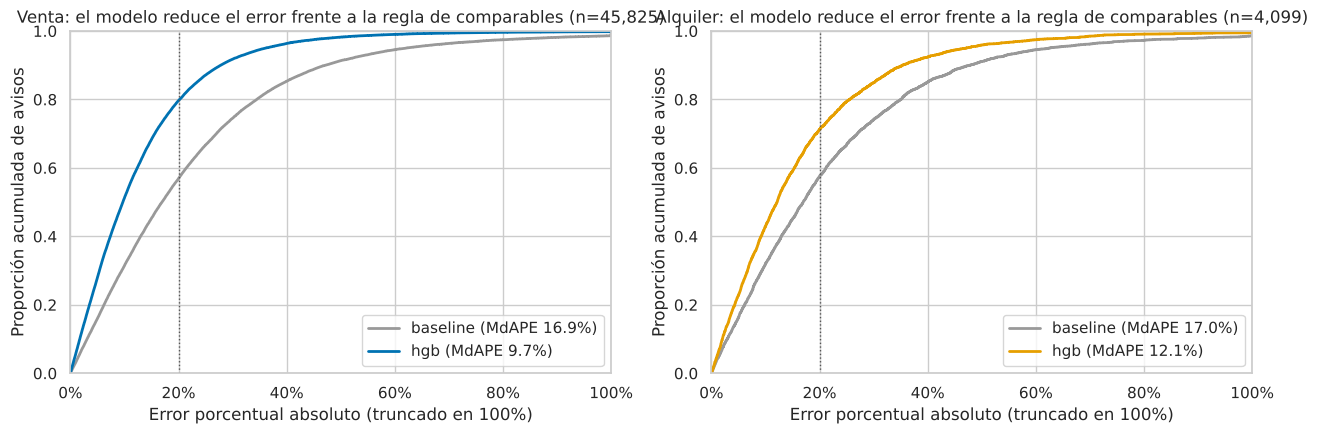

n  MdAPE_baseline_%  MdAPE_hgb_%
Tipo_Propiedad Casa             3,483.0000           23.7000      15.4000
               Departamento    37,509.0000           16.1000       9.1000
               PH               4,833.0000           19.9000      12.3000
Quintil_precio Q1 (más barato)  9,227.0000           16.2000       9.5000
               Q2               9,465.0000           14.3000       8.9000
               Q3               8,810.0000           15.3000       8.9000
               Q4               9,253.0000           17.8000       9.8000
               Q5 (más caro)    9,070.0000           21.8000      11.9000

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, op in zip(axs, ['Venta', 'Alquiler']):
    res = cv[op]
    for nombre, color in [('baseline', '#999999'), ('hgb', COLORES_OPERACION[op])]:
        ape = np.abs(np.exp(res[nombre] - res.y) - 1).clip(upper=1)
        ax.ecdf(ape, color=color, linewidth=2, label=f'{nombre} (MdAPE {100 * np.median(ape):.1f}%)')
    ax.axvline(.2, color='#555555', linestyle=':', linewidth=1)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
    ax.set(title=f'{op}: el modelo reduce el error frente a la regla de comparables (n={len(res):,})', xlabel='Error porcentual absoluto (truncado en 100%)',
           ylabel='Proporción acumulada de avisos', xlim=(0, 1))
    ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

# Error por segmento: dónde mejora el modelo y dónde sigue siendo débil.
v_cv = datos_modelo['Venta'][['Tipo_Propiedad', 'Precio_USD']].join(cv['Venta'])
v_cv['Quintil_precio'] = pd.qcut(v_cv.Precio_USD, 5, labels=['Q1 (más barato)', 'Q2', 'Q3', 'Q4', 'Q5 (más caro)'])
seg_err = pd.concat({col: pd.DataFrame({k: {'n': len(g), 'MdAPE_baseline_%': mod.metricas(g.y, g.baseline)['MdAPE_%'],
                                              'MdAPE_hgb_%': mod.metricas(g.y, g.hgb)['MdAPE_%']}
                                          for k, g in v_cv.groupby(col, observed=True)}).T
                     for col in ['Tipo_Propiedad', 'Quintil_precio']})
display(seg_err.round(1))

**Intervalos de predicción.** Un precio estimado sin incertidumbre induce a error: un aviso 8% por debajo de su estimación puede estar dentro del ruido normal del modelo. Se construye un intervalo empírico del 90% con los cuantiles 5 y 95 de los residuos fuera de muestra, y se verifica su **cobertura real**: para cada pliegue, los cuantiles se calculan con los residuos de los otros cuatro y se mide qué proporción de los avisos del pliegue cae adentro.

In [20]:
cobertura = []
for op, res in cv.items():
    residuo = res.y - res.hgb
    for k in range(5):
        q_inf, q_sup = np.quantile(residuo[res.pliegue.ne(k)], [.05, .95])
        dentro = residuo[res.pliegue.eq(k)].between(q_inf, q_sup)
        cobertura.append({'Operación': op, 'Pliegue': k, 'Cobertura_%': 100 * dentro.mean(),
                          'Ancho_relativo_%': 100 * (np.exp(q_sup) - np.exp(q_inf))})
cobertura = pd.DataFrame(cobertura)
display(cobertura.groupby('Operación')[['Cobertura_%', 'Ancho_relativo_%']].agg(['mean', 'min', 'max']).round(1))
mv = metricas_cv.loc['Venta']; ma = metricas_cv.loc['Alquiler']
lectura(f'El gradient boosting reduce el error mediano de venta de {mv.loc["baseline", "MdAPE_%"]:.1f}% (baseline de comparables) '
        f'a {mv.loc["hgb", "MdAPE_%"]:.1f}%, y deja dentro de ±20% al {mv.loc["hgb", "Dentro_20%"]:.0f}% de los avisos '
        f'(baseline: {mv.loc["baseline", "Dentro_20%"]:.0f}%). En alquiler la mejora es menor ({ma.loc["baseline", "MdAPE_%"]:.1f}% → '
        f'{ma.loc["hgb", "MdAPE_%"]:.1f}%), por la muestra mucho más chica. La mejora se repite en todos los pliegues. '
        'El modelo es más débil en casas y en las puntas de precio. El intervalo del 90% cubre lo prometido, pero es '
        f'ancho (alrededor de {cobertura.loc[cobertura.Operación.eq("Venta"), "Ancho_relativo_%"].mean():.0f}% del precio en venta): '
        'el modelo sirve para **priorizar avisos a revisar**, no para tasar una unidad individual.')

Cobertura_%                 Ancho_relativo_%                
                 mean     min     max             mean     min     max
Operación                                                             
Alquiler      89.9000 89.3000 91.7000          74.0000 73.3000 75.5000
Venta         90.0000 89.6000 90.5000          56.6000 56.4000 56.9000

**Interpretación.** El gradient boosting reduce el error mediano de venta de 16.9% (baseline de comparables) a 9.7%, y deja dentro de ±20% al 80% de los avisos (baseline: 57%). En alquiler la mejora es menor (17.0% → 12.1%), por la muestra mucho más chica. La mejora se repite en todos los pliegues. El modelo es más débil en casas y en las puntas de precio. El intervalo del 90% cubre lo prometido, pero es ancho (alrededor de 57% del precio en venta): el modelo sirve para **priorizar avisos a revisar**, no para tasar una unidad individual.

## 9. H6 — Particulares frente a inmobiliarias

> **H6:** las publicaciones de vendedores particulares tienen mayor probabilidad de estar subvaluadas que las publicadas por inmobiliarias, porque el particular suele tener menos información de mercado y, a veces, más urgencia.

**Medición de la subvaluación.** El `Indice_Subvaluacion` original compara cada aviso con la mediana de un grupo **que lo incluye**, lo que lo sesga hacia cero. Acá se usa el **índice fuera de muestra** del modelo HGB: `precio publicado / precio estimado − 1`, donde la estimación viene de un modelo que no vio ese aviso. El modelo **no usa** el tipo de vendedor, así que no puede absorber la diferencia que se quiere medir.

**Contraste.** Se define subvaluado como un índice de −15% o menos y se estima un **modelo de probabilidad lineal** con efectos fijos de barrio, tipo y ambientes, y errores por barrio. El coeficiente de `particular` es la diferencia de probabilidad en puntos porcentuales. Robustez: umbrales de −10% y −20%, el índice continuo y el índice original. En la base quedan menos de 600 ventas de particulares (1,3%): el tamaño muestral limita la precisión.

In [21]:
v6 = datos_modelo['Venta'].join(cv['Venta'][['y', 'hgb']])
v6['Subval_modelo'] = np.exp(v6.y - v6.hgb) - 1
v6['log_ratio'] = v6.y - v6.hgb
crudo = v6.groupby(v6.particular.map({1: 'Particular', 0: 'Inmobiliaria'})).agg(
    Avisos=('Subval_modelo', 'size'), Indice_mediano=('Subval_modelo', 'median'),
    Subvaluados_15=('Subval_modelo', lambda s: (s <= -.15).mean()), Sobrevaluados_15=('Subval_modelo', lambda s: (s >= .15).mean()))
display(crudo)

COLS_H6 = ['particular', 'Barrio_Normalizado', 'Tipo_Propiedad', 'Ambientes_Agrupado']
F_H6 = '{y} ~ particular + C(Barrio_Normalizado) + C(Tipo_Propiedad) + C(Ambientes_Agrupado)'
h6 = {}
for umbral in [-.10, -.15, -.20]:
    d = v6.assign(subvaluado=v6.Subval_modelo.le(umbral).astype(int))
    h6[f'Subvaluado ≤ {umbral:.0%} (modelo)'] = (ajustar_cluster(F_H6.format(y='subvaluado'), d, COLS_H6), +1)
h6['Índice continuo log(precio/estimado) (signo −)'] = (ajustar_cluster(F_H6.format(y='log_ratio'), v6, COLS_H6), -1)
d_orig = v6.dropna(subset=['Indice_Subvaluacion']).assign(subvaluado=lambda d: d.Indice_Subvaluacion.le(-.15).astype(int))
h6['Subvaluado ≤ −15% (índice original)'] = (ajustar_cluster(F_H6.format(y='subvaluado'), d_orig, COLS_H6), +1)
tabla_h6 = pd.DataFrame({k: {**contraste(m, 'particular', s), 'Signo_esperado': np.sign(m.params['particular']) == s}
                         for k, (m, s) in h6.items()}).T
display(tabla_h6[['beta', 'ic_inf', 'ic_sup', 'p_unilateral', 'n', 'Signo_esperado']])

r6 = contraste(h6['Subvaluado ≤ -15% (modelo)'][0], 'particular', +1)
base_inmob = crudo.loc['Inmobiliaria', 'Subvaluados_15']
registrar('H6', 'P(subvaluado ≤ −15%) mayor en particulares (mismo barrio, tipo y ambientes)', f'{100 * r6["beta"]:+.1f} p.p.',
          f'[{100 * r6["ic_inf"]:+.1f}, {100 * r6["ic_sup"]:+.1f}] p.p.', r6['p_unilateral'],
          f'{100 * r6["beta"]:+.1f} p.p. sobre una base de {base_inmob:.1%} en inmobiliarias',
          f'{tabla_h6.Signo_esperado.astype(int).sum()}/{len(tabla_h6)}', r6['n'], f'Índice fuera de muestra; {crudo.loc["Particular", "Avisos"]} particulares',
          signo_ok=r6['beta'] > 0)
lectura(f'Sin ajustar, el {crudo.loc["Particular", "Subvaluados_15"]:.1%} de los avisos de particulares queda 15% o más por '
        f'debajo de su precio estimado, contra el {base_inmob:.1%} de las inmobiliarias. Comparando dentro del mismo barrio, '
        f'tipo y ambientes, la diferencia es {100 * r6["beta"]:+.1f} p.p. (IC95% {100 * r6["ic_inf"]:+.1f} a {100 * r6["ic_sup"]:+.1f}). '
        'Los particulares también aparecen con más frecuencia **sobrevaluados**: publican con más dispersión, no solo más barato. '
        'Esa dispersión es compatible con menos información de mercado, pero también con atributos no observados '
        '(estado del inmueble, calidad) que el modelo no ve.')

,Avisos,Indice_mediano,Subvaluados_15,Sobrevaluados_15
particular,,,,
Inmobiliaria,45247,-0.0004,0.1435,0.1727
Particular,578,-0.0119,0.1920,0.1678


,beta,ic_inf,ic_sup,p_unilateral,n,Signo_esperado
Subvaluado ≤ -10% (modelo),0.0474,0.0044,0.0905,0.0157,45825,True
Subvaluado ≤ -15% (modelo),0.0431,0.0063,0.0798,0.0113,45825,True
Subvaluado ≤ -20% (modelo),0.0343,0.0044,0.0642,0.0128,45825,True
Índice continuo log(precio/estimado) (signo −),-0.0227,-0.0400,-0.0055,0.0055,45825,True
Subvaluado ≤ −15% (índice original),-0.0113,-0.0606,0.0380,0.6772,43376,False


**Interpretación.** Sin ajustar, el 19.2% de los avisos de particulares queda 15% o más por debajo de su precio estimado, contra el 14.4% de las inmobiliarias. Comparando dentro del mismo barrio, tipo y ambientes, la diferencia es +4.3 p.p. (IC95% +0.6 a +8.0). Los particulares también aparecen con más frecuencia **sobrevaluados**: publican con más dispersión, no solo más barato. Esa dispersión es compatible con menos información de mercado, pero también con atributos no observados (estado del inmueble, calidad) que el modelo no ve.

## 10. Indicadores consolidados, costos de la inversión e índice de priorización

### 10.1 Indicadores por aviso

Para cada venta de la base se materializan:

| Indicador | Definición |
|---|---|
| `Precio_Estimado_USD` | Predicción **fuera de muestra** del modelo HGB de venta |
| `Precio_Estimado_Inf_USD`, `Precio_Estimado_Sup_USD` | Intervalo empírico del 90% (sección 8) |
| `Indice_Subvaluacion_Modelo` | Precio publicado / estimado − 1. Negativo = por debajo de la referencia |
| `Subvaluacion_Fuera_Intervalo` | 1 si el precio publicado está por debajo del límite inferior del intervalo: la señal supera el ruido del modelo |
| `Alquiler_Estimado_USD` | Alquiler mensual que el modelo HGB de **alquiler** (entrenado con todos los alquileres de la base) asigna a la unidad en venta |
| `En_Soporte_Alquiler` | 1 si el segmento tiene ≥5 alquileres en la base y la superficie está dentro del rango observado en alquiler para su tipo. Fuera de soporte, el alquiler estimado es una extrapolación |
| `Rentabilidad_Bruta_Aviso` | 12 × alquiler estimado / precio publicado |
| `Expensas_Validas_USD` | `Expensas_USD_Imputada` del notebook 02, salvo que las expensas de un año superen el 6% del precio (el percentil 99,9 es 4,8%): son centinelas o errores de moneda y pasan a nulo |
| `Rentabilidad_Neta_Aviso` | Flujo neto anual / (precio × (1 + costos de compra)), escenario base de costos (sección 10.2) |
| `Rentabilidad_Neta_Optimista`, `Rentabilidad_Neta_Pesimista` | Ídem con los supuestos de costos optimistas y pesimistas |
| `TIR_10_Anios` | TIR de comprar, alquilar 10 años y vender al mismo precio en USD, con costos de compra y de venta (escenario base). Reemplaza al payback |

**Por qué rentabilidad por aviso.** Hasta la PE2 la rentabilidad solo existía por zona, con 139 combinaciones y 13.500 avisos sin dato. El modelo de alquiler permite asignarla a cada unidad, con su propia superficie, ambientes y amenities. Antes de usarla se valida contra las rentabilidades observadas por segmento.

In [22]:
res_v = cv['Venta']
residuo_v = res_v.y - res_v.hgb
q_inf, q_sup = np.quantile(residuo_v, [.05, .95])
avisos = datos_modelo['Venta'].copy()
avisos['Precio_Estimado_USD'] = np.exp(res_v.hgb)
avisos['Precio_Estimado_Inf_USD'] = avisos.Precio_Estimado_USD * np.exp(q_inf)
avisos['Precio_Estimado_Sup_USD'] = avisos.Precio_Estimado_USD * np.exp(q_sup)
avisos['Indice_Subvaluacion_Modelo'] = avisos.Precio_USD / avisos.Precio_Estimado_USD - 1
avisos['Subvaluacion_Fuera_Intervalo'] = avisos.Precio_USD.lt(avisos.Precio_Estimado_Inf_USD).astype(int)

alq_m = datos_modelo['Alquiler']
predecir_alquiler = mod.ajustar_hgb(alq_m, np.log(alq_m.Precio_USD.to_numpy()))
avisos['Alquiler_Estimado_USD'] = np.exp(predecir_alquiler(avisos))
n_alq_seg = alquileres.groupby(ind.CLAVES_SEGMENTO).size()
rango_sup = alquileres.groupby('Tipo_Propiedad').Superficie_Total_m2.quantile([.01, .99]).unstack()
soporte_seg = pd.Series(n_alq_seg.reindex(pd.MultiIndex.from_frame(avisos[ind.CLAVES_SEGMENTO])).to_numpy(),
                        index=avisos.index).fillna(0).ge(5)
soporte_sup = avisos.Superficie_Total_m2.between(avisos.Tipo_Propiedad.map(rango_sup[.01]), avisos.Tipo_Propiedad.map(rango_sup[.99]))
avisos['En_Soporte_Alquiler'] = (soporte_seg & soporte_sup).astype(int)
avisos['Rentabilidad_Bruta_Aviso'] = 12 * avisos.Alquiler_Estimado_USD / avisos.Precio_USD
avisos['Expensas_Validas_USD'] = avisos.Expensas_USD_Imputada.where(12 * avisos.Expensas_USD_Imputada <= .06 * avisos.Precio_USD)
# Rentabilidad neta con los costos de la inversión (sección 10.2); el escenario base es el principal.
args_flujo = (avisos.Alquiler_Estimado_USD, avisos.Precio_USD, avisos.Expensas_Validas_USD)
avisos['Rentabilidad_Neta_Aviso'] = ind.rentabilidad_neta(*args_flujo, ind.ESCENARIOS_COSTOS['Base'])
for escenario in ['Optimista', 'Pesimista']:
    avisos[f'Rentabilidad_Neta_{escenario}'] = ind.rentabilidad_neta(*args_flujo, ind.ESCENARIOS_COSTOS[escenario])
avisos['TIR_10_Anios'] = ind.tir_tenencia(*args_flujo, ind.ESCENARIOS_COSTOS['Base'])
avisos['Factor_Confianza'] = ind.factor_confianza(avisos)

# Validación: la rentabilidad modelada, agregada por segmento, debe reproducir la observada.
modelada = (avisos.loc[avisos.En_Soporte_Alquiler.eq(1)].groupby(ind.CLAVES_SEGMENTO).Rentabilidad_Bruta_Aviso.median()
            .rename('Bruta_modelo'))
val = segmentos.set_index(ind.CLAVES_SEGMENTO).join(modelada, how='inner')
rho_val = stats.spearmanr(val.Bruta, val.Bruta_modelo).statistic
sesgo_val = (val.Bruta_modelo / val.Bruta).median() - 1
print(f'Ventas con indicadores: {len(avisos):,} | en soporte de alquiler: {avisos.En_Soporte_Alquiler.mean():.1%} | '
      f'con rentabilidad neta: {avisos.Rentabilidad_Neta_Aviso.notna().mean():.1%} | expensas implausibles anuladas: '
      f'{(avisos.Expensas_USD_Imputada.notna() & avisos.Expensas_Validas_USD.isna()).sum()}')
print(f'Validación contra {len(val)} segmentos observados: Spearman={rho_val:.2f}, sesgo mediano modelo/observado={sesgo_val:+.1%}')
display(avisos.loc[avisos.En_Soporte_Alquiler.eq(1), ['Rentabilidad_Bruta_Aviso', 'Rentabilidad_Neta_Aviso',
                                                      'Indice_Subvaluacion_Modelo']].describe(percentiles=[.1, .25, .5, .75, .9]).T)

Ventas con indicadores: 45,825 | en soporte de alquiler: 73.3% | con rentabilidad neta: 97.7% | expensas implausibles anuladas: 31
Validación contra 129 segmentos observados: Spearman=0.70, sesgo mediano modelo/observado=+11.4%


,count,mean,std,min,10%,25%,50%,75%,90%,max
Rentabilidad_Bruta_Aviso,"33,584.0000",0.0670,0.0290,0.0067,0.0464,0.0536,0.0625,0.0739,0.0882,2.1470
Rentabilidad_Neta_Aviso,"33,414.0000",0.0437,0.0222,-0.0055,0.0268,0.0328,0.0401,0.0494,0.0612,0.5344
Indice_Subvaluacion_Modelo,"33,584.0000",0.0124,0.1738,-0.9780,-0.1694,-0.0869,-0.0011,0.0929,0.2038,8.6733


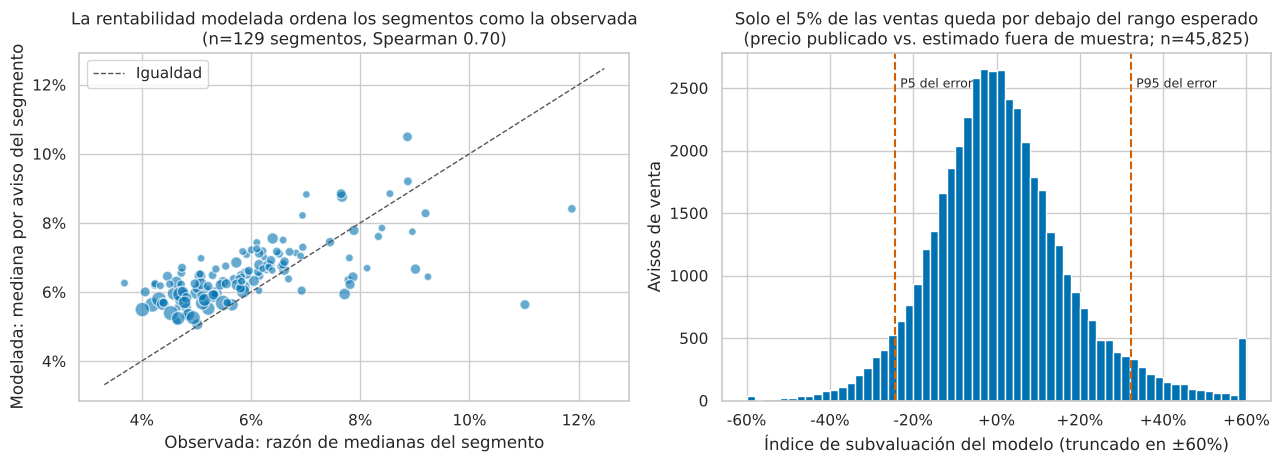

**Interpretación.** La rentabilidad modelada ordena los segmentos igual que la observada (Spearman 0.70), con un sesgo mediano de +11.4%. Ese sesgo existe porque las unidades que se alquilan no son iguales a las que se venden (más chicas y más equipadas). El indicador por aviso sirve para **comparar** unidades entre sí; su nivel absoluto hereda la incertidumbre del modelo de alquiler (MdAPE 12%). Solo el 5.0% de las ventas queda por debajo del intervalo del 90%: esas son las señales de precio que superan el ruido del modelo.

In [23]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
axs[0].scatter(val.Bruta, val.Bruta_modelo, s=10 + 3 * np.sqrt(val.n_alquiler) * 3, color='#0072B2', alpha=.6, edgecolor='white')
lim = [val[['Bruta', 'Bruta_modelo']].min().min() * .9, val[['Bruta', 'Bruta_modelo']].max().max() * 1.05]
axs[0].plot(lim, lim, color='#555555', linestyle='--', linewidth=1, label='Igualdad')
for ax_fmt in (axs[0].xaxis, axs[0].yaxis):
    ax_fmt.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
axs[0].set(xlabel='Observada: razón de medianas del segmento', ylabel='Modelada: mediana por aviso del segmento',
           title=f'La rentabilidad modelada ordena los segmentos como la observada\n(n={len(val)} segmentos, Spearman {rho_val:.2f})')
axs[0].legend(loc='upper left')
indice = avisos.Indice_Subvaluacion_Modelo.clip(-.6, .6)
axs[1].hist(indice, bins=60, color='#0072B2')
for q, etiqueta in [(np.exp(q_inf) - 1, 'P5 del error'), (np.exp(q_sup) - 1, 'P95 del error')]:
    axs[1].axvline(q, color='#D55E00', linestyle='--', linewidth=1.5)
    axs[1].annotate(etiqueta, (q, axs[1].get_ylim()[1] * .9), xytext=(4, 0), textcoords='offset points', fontsize=9)
axs[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:+.0%}'))
axs[1].set(xlabel='Índice de subvaluación del modelo (truncado en ±60%)', ylabel='Avisos de venta',
           title=f'Solo el {avisos.Subvaluacion_Fuera_Intervalo.mean():.0%} de las ventas queda por debajo del rango esperado\n'
             f'(precio publicado vs. estimado fuera de muestra; n={len(avisos):,})')
plt.tight_layout(); plt.show()
lectura(f'La rentabilidad modelada ordena los segmentos igual que la observada (Spearman {rho_val:.2f}), con un sesgo '
        f'mediano de {sesgo_val:+.1%}. Ese sesgo existe porque las unidades que se alquilan no son iguales a las que se '
        'venden (más chicas y más equipadas). El indicador por aviso sirve para **comparar** unidades entre sí; su nivel '
        f'absoluto hereda la incertidumbre del modelo de alquiler (MdAPE {ma.loc["hgb", "MdAPE_%"]:.0f}%). '
        f'Solo el {avisos.Subvaluacion_Fuera_Intervalo.mean():.1%} de las ventas queda por debajo del intervalo del 90%: '
        'esas son las señales de precio que superan el ruido del modelo.')

### 10.2 Costos de la inversión: de la rentabilidad bruta a la neta

La rentabilidad neta de la PE2 solo restaba expensas y un 1% de mantenimiento. Ahora incorpora los costos que enfrenta un inversor en CABA en 2026. Los supuestos están en `ind.SupuestosCostos` y se agrupan en tres escenarios. Las fuentes están en el README (sección "Costos de la inversión").

| Costo | Escenario base | Optimista – pesimista | Fuente o criterio |
|---|---|---|---|
| Vacancia | 1 mes por cada contrato de 24 | 0,5 – 2 meses | Una unidad tarda de 30 a 60 días en alquilarse, y la oferta en alquiler está en máximos (cerca de 17.000 unidades en septiembre de 2026) |
| Comisión por alquilar | 1 mes + IVA por contrato, a cargo del propietario | 1 mes – 1 mes + IVA | En CABA la comisión no se le puede cobrar al inquilino (Ley 5859) |
| Administración | 0% (gestión propia) | 0% – 5% del alquiler | Las inmobiliarias cobran entre 4% y 6% por administrar |
| Expensas | Ordinarias solo en la vacancia + extraordinarias del 10% de las ordinarias | 0% – 20% | Las ordinarias las paga el inquilino; las extraordinarias, el propietario |
| Mantenimiento | 1% del precio por año | 0,5% – 1,5% | Supuesto del grupo (PE2) |
| ABL | 0,2% del precio por año | 0,1% – 0,4% | Supuesto: se calcula sobre la valuación fiscal, que no está en el dataset |
| Ganancias | 0% | 0% | El alquiler de vivienda está exento para personas humanas desde el 1/1/2026 (Ley 27.802 y Decreto 406/2026) |
| Costos de compra | 8,6% del precio | 6% – 10% | Comisión 4% + IVA, escribano 2% + IVA y la mitad de sellos (2,7%). Un inversor no accede a la exención por vivienda única |
| Costos de venta | 5,4% del precio | 4,5% – 6% | Comisión 3% + IVA, la mitad de sellos y certificados |

**Definiciones.**
- `Rentabilidad_Neta_Aviso` = flujo neto anual / (precio × (1 + costos de compra)). Mide el retorno sobre lo que realmente se invierte.
- `TIR_10_Anios` es la tasa interna de retorno de comprar, alquilar 10 años y vender al mismo precio en dólares, con costos de compra y de venta. **Reemplaza al payback** (1 / rentabilidad), que no incluía esos costos ni el valor del dinero en el tiempo. **No es un pronóstico**: supone precio y alquiler constantes en dólares y no suma valorización.
- **Liquidez.** El dataset es una foto: no dice cuánto tarda en venderse una unidad. Por eso la liquidez entra de dos formas: los costos de salida dentro de la TIR y la vacancia del escenario pesimista. Hay que tener en cuenta que el crédito hipotecario financia una parte chica de las compras (17% de las escrituras de CABA en agosto de 2026), lo que limita la demanda al momento de revender.

**Corrección respecto de la versión anterior.** La rentabilidad neta restaba 12 meses de expensas ordinarias, como si las pagara el propietario. En un alquiler las paga el inquilino; el propietario solo las paga mientras la unidad está vacía. La tabla de abajo muestra cuánto cambia el resultado con cada definición.

In [24]:
supuestos = pd.DataFrame({n: vars(s) for n, s in ind.ESCENARIOS_COSTOS.items()}).drop(index='nombre')
display(supuestos)

en_soporte = avisos.En_Soporte_Alquiler.eq(1) & avisos.Rentabilidad_Neta_Aviso.notna()
neta_pe2 = (12 * avisos.Alquiler_Estimado_USD - 12 * avisos.Expensas_Validas_USD - .01 * avisos.Precio_USD) / avisos.Precio_USD
filas = [{'Definición': 'PE2: expensas ordinarias completas + 1% de mantenimiento', 'Neta_mediana': neta_pe2[en_soporte].median(),
          'TIR_10_mediana': np.nan, 'Neta_menor_3%': (neta_pe2[en_soporte] < .03).mean()}]
tir_escenario = {}
for nombre, s in ind.ESCENARIOS_COSTOS.items():
    neta = ind.rentabilidad_neta(*args_flujo, s)[en_soporte]
    tir_escenario[nombre] = ind.tir_tenencia(*args_flujo, s)[en_soporte]
    filas.append({'Definición': f'Costos {nombre.lower()}', 'Neta_mediana': neta.median(),
                  'TIR_10_mediana': tir_escenario[nombre].median(), 'Neta_menor_3%': (neta < .03).mean()})
escenarios_costos = pd.DataFrame(filas).set_index('Definición')
bruta_mediana = avisos.loc[en_soporte, 'Rentabilidad_Bruta_Aviso'].median()
escenarios_costos.insert(0, 'Bruta_mediana', bruta_mediana)
escenarios_costos['Brecha_bruta_neta_pp'] = 100 * (escenarios_costos.Bruta_mediana - escenarios_costos.Neta_mediana)
display(escenarios_costos)

# ¿Se mantiene el orden entre zonas una vez descontados los costos?
por_zona = pd.DataFrame({f'Neta {n.lower()}': ind.rentabilidad_neta(*args_flujo, s)[en_soporte]
                         for n, s in ind.ESCENARIOS_COSTOS.items()}).assign(
    Bruta=avisos.loc[en_soporte, 'Rentabilidad_Bruta_Aviso'], Zona=ind.zona_h1(avisos.loc[en_soporte, 'Barrio_Normalizado']))
zona_tabla = por_zona.groupby('Zona').agg(['median', 'size']).loc[['Sur/Oeste', 'Norte premium', 'Resto']]
display(zona_tabla.xs('median', axis=1, level=1).assign(n=zona_tabla[('Bruta', 'size')]))

,Optimista,Base,Pesimista
meses_contrato,24,24,24
meses_vacancia,0.5000,1.0000,2.0000
meses_comision_alquiler,1.0000,1.2100,1.2100
administracion_pct_alquiler,0.0000,0.0000,0.0500
expensas_ordinarias_propietario,False,False,False
expensas_extraordinarias_pct,0.0000,0.1000,0.2000
mantenimiento_pct_precio,0.0050,0.0100,0.0150
abl_pct_precio,0.0010,0.0020,0.0040
ganancias_pct_renta,0.0000,0.0000,0.0000
costos_entrada_pct,0.0600,0.0860,0.1000


,Bruta_mediana,Neta_mediana,TIR_10_mediana,Neta_menor_3%,Brecha_bruta_neta_pp
Definición,,,,,
PE2: expensas ordinarias completas + 1% de mantenimiento,0.0625,0.0420,NaN,0.1489,2.0454
Costos optimista,0.0625,0.0495,0.0413,0.0375,1.3005
Costos base,0.0625,0.0401,0.0288,0.1704,2.2403
Costos pesimista,0.0625,0.0273,0.0136,0.5994,3.5181


,Neta optimista,Neta base,Neta pesimista,Bruta,n
Zona,,,,,
Sur/Oeste,0.0533,0.0437,0.0305,0.0668,5292
Norte premium,0.0452,0.0361,0.0238,0.0577,8571
Resto,0.0504,0.0410,0.0281,0.0636,19551


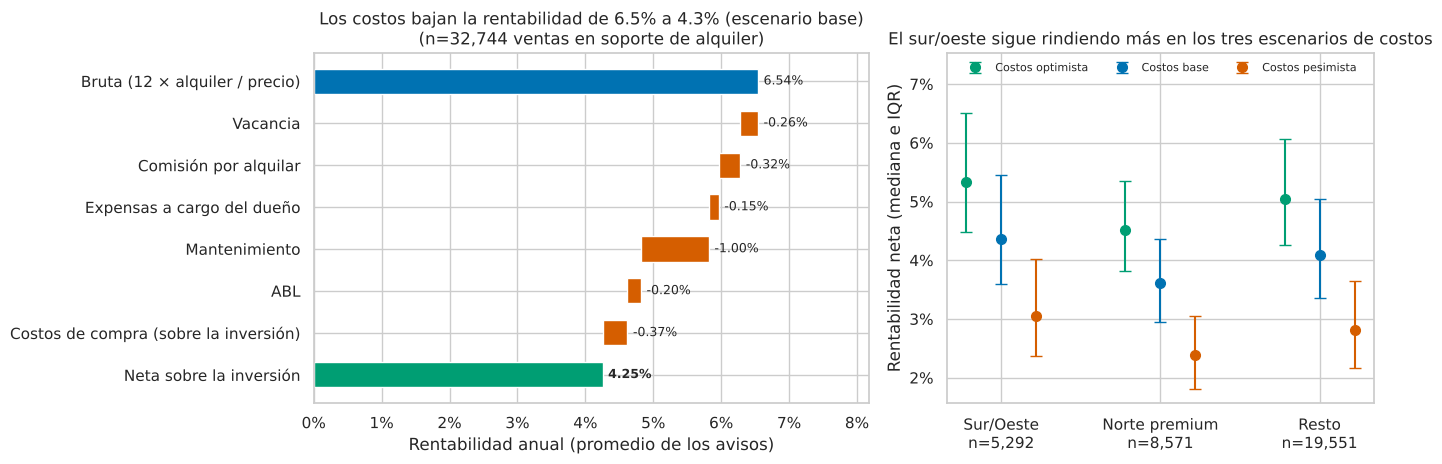

**Interpretación.** En el escenario base, los costos llevan la rentabilidad mediana de 6.25% bruta a 4.01% neta (2.2 puntos menos). Según el escenario, la neta mediana va de 2.73% a 4.95%. Los que más pesan son mantenimiento (1.00%), costos de compra (sobre la inversión) (0.37%), comisión por alquilar (0.32%), en promedio y sobre la inversión. La definición de la PE2 daba 4.20%: restaba las expensas ordinarias completas, que en un alquiler paga el inquilino, y no restaba vacancia, comisiones, ABL ni costos de compra. La TIR a 10 años, sin valorización, es de 2.88% en el escenario base: queda por debajo de la neta porque al final se pagan los costos de venta. Como referencia de mercado, Zonaprop estima una rentabilidad bruta de 5,7% anual para CABA (septiembre de 2026), y los operadores consultados por la prensa ubican la neta entre 1 y 1,5 puntos por debajo. Nuestra brecha es mayor porque también descuenta los costos de compra y un 1% anual de mantenimiento. El orden entre zonas no cambia con los costos: el sur/oeste rinde más que el norte premium en los tres escenarios.

In [25]:
# Puente de la bruta a la neta (escenario base). Se usan promedios, que suman exacto, sobre avisos con bruta entre P1 y P99.
b = avisos.loc[en_soporte]
b = b.loc[b.Rentabilidad_Bruta_Aviso.between(*b.Rentabilidad_Bruta_Aviso.quantile([.01, .99]))]
comp = ind.componentes_flujo(b.Alquiler_Estimado_USD, b.Precio_USD, b.Expensas_Validas_USD, ind.ESCENARIOS_COSTOS['Base'])
pasos = {'Bruta (12 × alquiler / precio)': (12 * b.Alquiler_Estimado_USD / b.Precio_USD).mean()}
for col, etiqueta in [('Vacancia', 'Vacancia'), ('Comision_alquiler', 'Comisión por alquilar'),
                      ('Expensas_propietario', 'Expensas a cargo del dueño'), ('Mantenimiento', 'Mantenimiento'), ('ABL', 'ABL')]:
    pasos[etiqueta] = -(comp[col] / b.Precio_USD).mean()
flujo_sobre_precio = sum(pasos.values())
neta_media = (ind.flujo_neto_anual(b.Alquiler_Estimado_USD, b.Precio_USD, b.Expensas_Validas_USD) / (b.Precio_USD * 1.086)).mean()
pasos['Costos de compra (sobre la inversión)'] = neta_media - flujo_sobre_precio

fig, axs = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1.3, 1]})
acumulado, etiquetas_p = 0.0, list(pasos)
for i, (etiqueta, valor) in enumerate(pasos.items()):
    inicio = 0 if i == 0 else acumulado
    color = '#0072B2' if i == 0 else '#D55E00'
    axs[0].barh(i, valor, left=inicio, color=color, height=.6)
    axs[0].annotate(f'{valor:+.2%}' if i else f'{valor:.2%}', (inicio + valor if valor > 0 else inicio, i),
                    xytext=(4, 0), textcoords='offset points', va='center', fontsize=9)
    acumulado = inicio + valor
axs[0].barh(len(pasos), acumulado, color='#009E73', height=.6)
axs[0].annotate(f'{acumulado:.2%}', (acumulado, len(pasos)), xytext=(4, 0), textcoords='offset points', va='center', fontsize=9, fontweight='bold')
axs[0].set_yticks(range(len(pasos) + 1), etiquetas_p + ['Neta sobre la inversión'])
axs[0].invert_yaxis()
axs[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
axs[0].set(xlabel='Rentabilidad anual (promedio de los avisos)', xlim=(0, pasos['Bruta (12 × alquiler / precio)'] * 1.25),
           title=f'Los costos bajan la rentabilidad de {pasos["Bruta (12 × alquiler / precio)"]:.1%} a {acumulado:.1%} (escenario base)\n'
                 f'(n={len(b):,} ventas en soporte de alquiler)')

zonas_plot = ['Sur/Oeste', 'Norte premium', 'Resto']
colores_esc = {'Optimista': '#009E73', 'Base': '#0072B2', 'Pesimista': '#D55E00'}
for k, nombre in enumerate(ind.ESCENARIOS_COSTOS):
    col = f'Neta {nombre.lower()}'
    g = por_zona.groupby('Zona')[col].quantile([.25, .5, .75]).unstack().loc[zonas_plot]
    xs = np.arange(len(zonas_plot)) + (k - 1) * .22
    axs[1].errorbar(xs, g[.5], yerr=[g[.5] - g[.25], g[.75] - g[.5]], fmt='o', color=colores_esc[nombre], capsize=4,
                    markersize=7, label=f'Costos {nombre.lower()}')
n_zona = por_zona.Zona.value_counts()
axs[1].set_xticks(range(len(zonas_plot)), [f'{z}\nn={n_zona[z]:,}' for z in zonas_plot])
axs[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
axs[1].set(ylabel='Rentabilidad neta (mediana e IQR)',
           title='El sur/oeste sigue rindiendo más en los tres escenarios de costos')
axs[1].set_ylim(top=axs[1].get_ylim()[1] + .008)
axs[1].legend(fontsize=8, loc='upper center', ncol=3, frameon=False)
plt.tight_layout(); plt.show()

ec = escenarios_costos
lectura(f'En el escenario base, los costos llevan la rentabilidad mediana de {ec.Bruta_mediana.iloc[0]:.2%} bruta a '
        f'{ec.loc["Costos base", "Neta_mediana"]:.2%} neta ({ec.loc["Costos base", "Brecha_bruta_neta_pp"]:.1f} puntos menos). '
        f'Según el escenario, la neta mediana va de {ec.loc["Costos pesimista", "Neta_mediana"]:.2%} a {ec.loc["Costos optimista", "Neta_mediana"]:.2%}. '
        f'Los que más pesan son {", ".join(f"{k.lower()} ({-v:.2%})" for k, v in sorted(list(pasos.items())[1:], key=lambda kv: kv[1])[:3])}, '
        'en promedio y sobre la inversión. '
        f'La definición de la PE2 daba {ec.iloc[0].Neta_mediana:.2%}: restaba las expensas ordinarias completas, que en un alquiler paga el inquilino, '
        'y no restaba vacancia, comisiones, ABL ni costos de compra. '
        f'La TIR a 10 años, sin valorización, es de {ec.loc["Costos base", "TIR_10_mediana"]:.2%} en el escenario base: queda por debajo de la neta '
        'porque al final se pagan los costos de venta. Como referencia de mercado, Zonaprop estima una rentabilidad bruta de 5,7% anual para CABA '
        '(septiembre de 2026), y los operadores consultados por la prensa ubican la neta entre 1 y 1,5 puntos por debajo. Nuestra brecha es mayor '
        'porque también descuenta los costos de compra y un 1% anual de mantenimiento. '
        'El orden entre zonas no cambia con los costos: el sur/oeste rinde más que el norte premium en los tres escenarios.')

### 10.3 Índice de priorización (antes "score de oportunidad") y su sensibilidad

**Qué es y qué no es.** El índice ordena los avisos para decidir **cuáles revisar primero**: combina la rentabilidad neta del aviso y su subvaluación fuera de muestra, ponderadas por la confianza en el dato. No es una recomendación de compra. Se renombró porque "score de oportunidad" sugería una regla de decisión validada, y no lo es: validarla requeriría saber qué pasó después con los avisos (si se vendieron, a qué precio, cuánto rindieron), y con una foto de cuatro días ese dato no existe. Lo que sí se puede medir es **cuánto depende el orden de los supuestos**, y eso se hace abajo.

Respecto del score de la PE2 cambian cuatro cosas, cada una por un problema documentado:

1. **Componentes por aviso:** rentabilidad neta del aviso con los costos de la inversión (antes: de la zona, sin costos) y subvaluación fuera de muestra (antes: contra un grupo que incluía al propio aviso).
2. **Normalización por percentiles** en lugar de min-max: un solo error de carga extremo ya no comprime al resto de la escala.
3. **Universo explícito:** ventas en soporte de alquiler, con rentabilidad neta calculable, dentro del presupuesto del interlocutor (USD 80.000–250.000). Los avisos con precio/m² menor al 40% de su grupo (`Flag_Precio_m2_Muy_Bajo`) se apartan **para revisión manual**: con un precio así es más probable un error de carga que una oportunidad.
4. **Nombre y columnas:** `Indice_Priorizacion` y `Orden_Revision` reemplazan a `Score_Oportunidad_v2` y `Ranking`.

`Indice_Priorizacion = 100 × (0,5 × percentil(rentabilidad neta) + 0,5 × percentil(−subvaluación)) × Factor_Confianza`

Los pesos 50/50, el factor 0,6 y los supuestos de costos son **supuestos**, no resultados. La tabla mide cuánto cambia el top 100 si se modifican.

In [26]:
en_universo = (avisos.En_Soporte_Alquiler.eq(1) & avisos.Rentabilidad_Neta_Aviso.notna()
               & avisos.Precio_USD.between(*PRESUPUESTO_USD))
revision_manual = en_universo & avisos.Flag_Precio_m2_Muy_Bajo.eq(1)
universo = avisos.loc[en_universo & ~revision_manual].copy()
print(f'Universo de la priorización: {len(universo):,} ventas | apartadas para revisión manual: {revision_manual.sum():,} | '
      f'factor de confianza 0: {(universo.Factor_Confianza == 0).sum():,}')

def calcular_indice(datos, peso=.5, metodo='rango', valor_no_critico=.6, rentabilidad='Rentabilidad_Neta_Aviso'):
    confianza = ind.factor_confianza(datos, valor_no_critico)
    return ind.indice_priorizacion(datos[rentabilidad], datos.Indice_Subvaluacion_Modelo, confianza, peso, metodo)

universo['Indice_Priorizacion'] = calcular_indice(universo)
universo['Orden_Revision'] = universo.Indice_Priorizacion.rank(ascending=False, method='first').astype(int)
avisos['Indice_Priorizacion'] = universo.Indice_Priorizacion
avisos['Orden_Revision'] = universo.Orden_Revision
avisos['En_Universo_Priorizacion'] = en_universo.astype(int)
avisos['Revision_Manual'] = revision_manual.astype(int)

TOP = 100
escenarios = {'Base (50/50, percentiles, 0,6)': {},
              'Peso rentabilidad 25%': {'peso': .25}, 'Peso rentabilidad 75%': {'peso': .75},
              'Solo rentabilidad': {'peso': 1.0}, 'Solo subvaluación': {'peso': 0.0},
              'Normalización min-max': {'metodo': 'minmax'}, 'Factor no crítico 0,8': {'valor_no_critico': .8},
              'Factor no crítico 0,4': {'valor_no_critico': .4},
              'Costos optimistas': {'rentabilidad': 'Rentabilidad_Neta_Optimista'},
              'Costos pesimistas': {'rentabilidad': 'Rentabilidad_Neta_Pesimista'}}
base_score = universo.Indice_Priorizacion
top_base = set(base_score.nlargest(TOP).index)
sens = []
for nombre, params in escenarios.items():
    s = calcular_indice(universo, **params)
    top = set(s.nlargest(TOP).index)
    sens.append({'Escenario': nombre, 'Spearman_vs_base': stats.spearmanr(base_score, s).statistic,
                 f'Coincidencia_top{TOP}_%': 100 * len(top & top_base) / TOP,
                 f'Barrios_en_top{TOP}': universo.loc[list(top), 'Barrio_Normalizado'].nunique(),
                 f'Rent_neta_mediana_top{TOP}': universo.loc[list(top), 'Rentabilidad_Neta_Aviso'].median(),
                 f'Subval_mediana_top{TOP}': universo.loc[list(top), 'Indice_Subvaluacion_Modelo'].median()})
sens = pd.DataFrame(sens).set_index('Escenario')
display(sens)

# Umbral: ¿qué pasaría si no se apartaran los precios muy bajos?
con_bajos = avisos.loc[en_universo].copy()
s_bajos = calcular_indice(con_bajos)
top_bajos = s_bajos.nlargest(TOP).index
print(f'Si no se apartaran los precios/m² muy bajos, ocuparían {con_bajos.loc[top_bajos, "Flag_Precio_m2_Muy_Bajo"].sum()} '
      f'de los primeros {TOP} lugares.')

Universo de la priorización: 21,356 ventas | apartadas para revisión manual: 37 | factor de confianza 0: 33


,Spearman_vs_base,Coincidencia_top100_%,Barrios_en_top100,Rent_neta_mediana_top100,Subval_mediana_top100
Escenario,,,,,
"Base (50/50, percentiles, 0,6)",1.0000,100.0000,21,0.0812,-0.3179
Peso rentabilidad 25%,0.9664,83.0000,23,0.0758,-0.3242
Peso rentabilidad 75%,0.9729,81.0000,21,0.0883,-0.2991
Solo rentabilidad,0.9096,12.0000,7,0.1408,-0.0575
Solo subvaluación,0.8798,51.0000,22,0.0672,-0.3588
Normalización min-max,0.8287,53.0000,17,0.1314,-0.2432
"Factor no crítico 0,8",0.9753,100.0000,21,0.0812,-0.3179
"Factor no crítico 0,4",0.9738,100.0000,21,0.0812,-0.3179
Costos optimistas,0.9996,99.0000,21,0.0809,-0.3179


Si no se apartaran los precios/m² muy bajos, ocuparían 11 de los primeros 100 lugares.


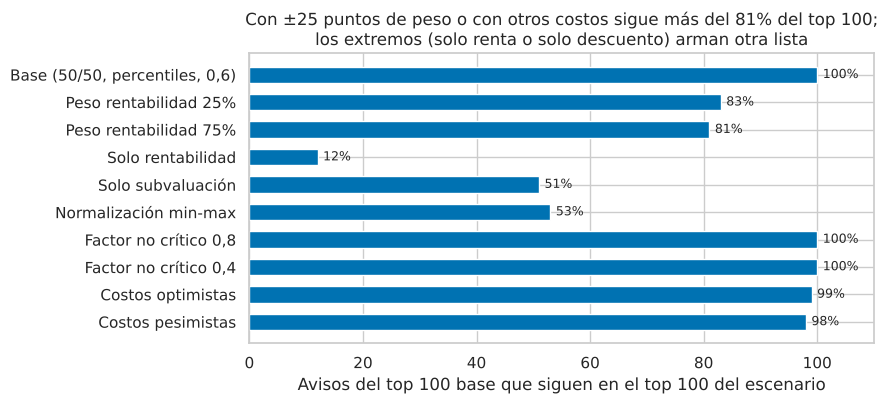

,Item_ID,Barrio_Normalizado,Tipo_Propiedad,Ambientes,Superficie_Total_m2,Precio_USD,Precio_Estimado_USD,Indice_Subvaluacion_Modelo,Alquiler_Estimado_USD,Rentabilidad_Neta_Aviso,Factor_Confianza,Indice_Priorizacion
14983,MLA3367197430,Balvanera,Departamento,5.0000,116.0000,"115,000.0000","186,389.2080",-0.3830,"1,921.8960",0.1520,1.0000,99.7070
13786,MLA3720093324,Balvanera,Departamento,4.0000,114.0000,"90,000.0000","133,806.8690",-0.3270,"1,707.0430",0.1770,1.0000,99.5720
14917,MLA1857301281,Balvanera,Departamento,6.0000,175.0000,"155,000.0000","294,289.5810",-0.4730,"1,885.6280",0.1110,1.0000,99.5670
13967,MLA3389362552,Balvanera,Departamento,4.0000,82.0000,"90,000.0000","136,095.5140",-0.3390,"1,256.9030",0.1280,1.0000,99.4710
39675,MLA3640752332,Villa del Parque,Departamento,2.0000,100.0000,"110,000.0000","200,352.7070",-0.4510,"1,254.2730",0.1030,1.0000,99.4690
14493,MLA3607005646,Balvanera,Departamento,3.0000,73.0000,"85,000.0000","122,284.8320",-0.3050,"1,819.8390",0.2010,1.0000,99.4150
23094,MLA1787361657,Flores,Departamento,4.0000,146.0000,"155,000.0000","228,819.5820",-0.3230,"2,217.4060",0.1310,1.0000,99.3960
10917,MLA2571529242,Balvanera,Departamento,5.0000,128.0000,"128,000.0000","182,915.1070",-0.3000,"2,555.0700",0.1900,1.0000,99.3540
4983,MLA1809444245,Flores,Departamento,4.0000,146.0000,"155,000.0000","268,017.2720",-0.4220,"1,718.0620",0.0970,1.0000,99.3510
25209,MLA1795359867,Monserrat,Departamento,3.0000,64.0000,"89,000.0000","132,246.4220",-0.3270,"1,190.0520",0.1210,1.0000,99.3440


**Interpretación.** Cambiar el peso de la rentabilidad a 25% o 75% mantiene entre el 81% y el 83% del top 100. El orden general es más estable que la cabeza (Spearman ≥ 0.97): los primeros lugares dependen de los pesos, así que el ranking debe leerse como una **lista corta para revisar**, no como un orden exacto. Cambiar los supuestos de costos mantiene entre el 98% y el 99% del top: los costos bajan el nivel de la rentabilidad, pero cambian poco el orden. Los casos extremos (solo rentabilidad o solo subvaluación) seleccionan avisos distintos: el inversor tiene que decidir cuánto pesa cada objetivo. El factor de confianza casi no cambia el top, porque las anomalías no críticas son en su mayoría de expensas y amenities. Apartar los precios muy bajos es la decisión de mayor impacto: sin ella, posibles errores de carga ocuparían la cabeza del ranking.

In [27]:
fig, ax = plt.subplots(figsize=(9, 4.2))
s = sens.iloc[::-1]
ax.barh(s.index, s[f'Coincidencia_top{TOP}_%'], color='#0072B2', height=.6)
for y, v in enumerate(s[f'Coincidencia_top{TOP}_%']):
    ax.annotate(f'{v:.0f}%', (v, y), xytext=(4, 0), textcoords='offset points', va='center', fontsize=9)
ax.set(xlim=(0, 110), xlabel=f'Avisos del top {TOP} base que siguen en el top {TOP} del escenario',
       title=f'Con ±25 puntos de peso o con otros costos sigue más del {sens.drop(index=["Solo rentabilidad", "Solo subvaluación", "Normalización min-max"]).iloc[1:][f"Coincidencia_top{TOP}_%"].min():.0f}% del top {TOP};\n'
             'los extremos (solo renta o solo descuento) arman otra lista')
plt.tight_layout(); plt.show()

cols_top = ['Item_ID', 'Barrio_Normalizado', 'Tipo_Propiedad', 'Ambientes', 'Superficie_Total_m2', 'Precio_USD',
            'Precio_Estimado_USD', 'Indice_Subvaluacion_Modelo', 'Alquiler_Estimado_USD', 'Rentabilidad_Neta_Aviso',
            'Factor_Confianza', 'Indice_Priorizacion']
display(universo.sort_values('Orden_Revision')[cols_top].head(15).round(3))
lectura(f'Cambiar el peso de la rentabilidad a 25% o 75% mantiene entre el {sens.iloc[1:3][f"Coincidencia_top{TOP}_%"].min():.0f}% y el '
        f'{sens.iloc[1:3][f"Coincidencia_top{TOP}_%"].max():.0f}% del top {TOP}. El orden general es más estable que la cabeza '
        f'(Spearman ≥ {sens.iloc[1:3].Spearman_vs_base.min():.2f}): los primeros lugares dependen de los pesos, así que el ranking '
        'debe leerse como una **lista corta para revisar**, no como un orden exacto. '
        f'Cambiar los supuestos de costos mantiene entre el {sens.loc[["Costos optimistas", "Costos pesimistas"], f"Coincidencia_top{TOP}_%"].min():.0f}% y el '
        f'{sens.loc[["Costos optimistas", "Costos pesimistas"], f"Coincidencia_top{TOP}_%"].max():.0f}% del top: los costos bajan el nivel de la rentabilidad, pero cambian poco el orden. Los casos extremos (solo rentabilidad o solo '
        'subvaluación) seleccionan avisos distintos: el inversor tiene que decidir cuánto pesa cada objetivo. '
        'El factor de confianza casi no cambia el top, porque las anomalías no críticas son en su mayoría de expensas y amenities. '
        'Apartar los precios muy bajos es la decisión de mayor impacto: sin ella, posibles errores de carga ocuparían la cabeza del ranking.')

### 10.4 Indicadores por barrio

Tabla consolidada para el dashboard. Cada indicador informa su denominador: un barrio con pocos alquileres tiene una rentabilidad observada poco confiable, aunque la modelada exista.

In [28]:
def mediana_si(datos, columna, minimo=5):
    return datos[columna].median() if datos[columna].notna().sum() >= minimo else np.nan

filas = []
for barrio, g in base.groupby('Barrio_Normalizado'):
    gv, ga = g.loc[g.venta.eq(1)], g.loc[g.venta.eq(0)]
    av = avisos.loc[avisos.Barrio_Normalizado.eq(barrio)]
    soporte = av.loc[av.En_Soporte_Alquiler.eq(1)]
    seg_b = segmentos.loc[segmentos.Barrio_Normalizado.eq(barrio)]
    filas.append({'Barrio': barrio, 'Comuna': ind.BARRIO_A_COMUNA[barrio], 'Zona_H1': ind.zona_h1(pd.Series([barrio]))[0],
                  'Ventas': len(gv), 'Alquileres': len(ga),
                  'USD_m2_venta_mediana': (gv.Precio_USD / gv.Superficie_Total_m2).median(),
                  'USD_m2_alquiler_mediana': mediana_si(ga.assign(m2=ga.Precio_USD / ga.Superficie_Total_m2), 'm2'),
                  'Precio_venta_mediano': gv.Precio_USD.median(),
                  'Segmentos_observados': len(seg_b), 'Rent_bruta_observada': seg_b.Bruta.median() if len(seg_b) else np.nan,
                  'Ventas_en_soporte': len(soporte), 'Rent_bruta_modelo': mediana_si(soporte, 'Rentabilidad_Bruta_Aviso'),
                  'Rent_neta_modelo': mediana_si(soporte, 'Rentabilidad_Neta_Aviso'),
                  'Rent_neta_pesimista_modelo': mediana_si(soporte, 'Rentabilidad_Neta_Pesimista'),
                  'TIR_10_modelo': mediana_si(soporte, 'TIR_10_Anios'),
                  'Pct_subvaluadas_fuera_intervalo': av.Subvaluacion_Fuera_Intervalo.mean(),
                  'Avisos_priorizables': int(universo.Barrio_Normalizado.eq(barrio).sum()),
                  'Delitos_1000m_mediana': gv.Cantidad_Delitos_1000m.median(), 'Dist_subte_m_mediana': gv.Distancia_Subte_m.median(),
                  'Verde_1000m_m2_mediana': gv.Superficie_Verde_1000m_m2.median(), 'Confort_mediano': gv.Tasa_Confort_Amenities.median(),
                  'Latitud': gv.Latitud.median(), 'Longitud': gv.Longitud.median()})
barrios = pd.DataFrame(filas).set_index('Barrio')
display(barrios.sort_values('Rent_neta_modelo', ascending=False).head(12)[
    ['Zona_H1', 'Ventas', 'Alquileres', 'USD_m2_venta_mediana', 'Rent_bruta_observada', 'Rent_bruta_modelo', 'Rent_neta_modelo',
     'Pct_subvaluadas_fuera_intervalo', 'Avisos_priorizables']])

,Zona_H1,Ventas,Alquileres,USD_m2_venta_mediana,Rent_bruta_observada,Rent_bruta_modelo,Rent_neta_modelo,Pct_subvaluadas_fuera_intervalo,Avisos_priorizables
Barrio,,,,,,,,,
Villa Lugano,Sur/Oeste,907,41,921.0526,0.0694,0.0954,0.0685,0.0959,147
La Boca,Sur/Oeste,343,14,"1,250.0000",0.0887,0.0920,0.0640,0.0991,17
Balvanera,Resto,2018,104,"1,589.8718",0.0702,0.0820,0.0557,0.0476,1054
Monserrat,Resto,1058,78,"1,772.2332",0.0788,0.0750,0.0501,0.0558,477
San Nicolás,Resto,807,49,"1,733.3333",0.0629,0.0726,0.0474,0.0669,414
Constitución,Resto,384,18,"1,230.7692",0.0651,0.0710,0.0465,0.0599,6
San Cristóbal,Resto,1060,33,"1,740.5330",0.0678,0.0703,0.0460,0.0368,257
Floresta,Sur/Oeste,676,35,"1,448.3240",0.0592,0.0679,0.0442,0.0725,197
Barracas,Sur/Oeste,990,33,"1,744.4444",0.0681,0.0676,0.0441,0.0747,235


## 11. Segmentación de barrios

**Pregunta:** ¿los barrios se agrupan en perfiles de inversión reconocibles, que el inversor pueda usar para orientar la búsqueda antes de mirar avisos? Se agrupan con **k-means** según cinco indicadores estandarizados: precio de entrada (log USD/m² de venta), rentabilidad neta modelada, delitos del entorno, distancia al subte y superficie verde. Solo entran barrios con al menos 30 ventas en soporte de alquiler.

**Validación de la segmentación** (la consigna exige estabilidad, interpretación y utilidad):
- La cantidad de grupos se elige por **silhouette**.
- **Estabilidad:** 200 réplicas bootstrap que remuestrean los avisos de cada barrio, recalculan sus indicadores y vuelven a agrupar. El índice de Rand ajustado (ARI) contra la segmentación original mide si los grupos son una estructura de los datos o un artefacto del ruido (1 = idénticos, 0 = azar).

In [29]:
VARS_SEG = {'log_m2_venta': 'Precio de entrada', 'Rent_neta_modelo': 'Rentabilidad neta', 'log_delitos': 'Delitos',
            'log_subte': 'Distancia al subte', 'log_verde': 'Verde'}
elegibles = barrios.index[barrios.Ventas_en_soporte.ge(30)]

def features_barrio(av):
    d = av.loc[av.En_Soporte_Alquiler.eq(1) & av.Barrio_Normalizado.isin(elegibles)]
    d = pd.DataFrame({'Barrio_Normalizado': d.Barrio_Normalizado, 'log_m2_venta': np.log(d.Precio_USD / d.Superficie_Total_m2),
                      'Rent_neta_modelo': d.Rentabilidad_Neta_Aviso, 'log_delitos': np.log1p(d.Cantidad_Delitos_1000m),
                      'log_subte': np.log1p(d.Distancia_Subte_m), 'log_verde': np.log1p(d.Superficie_Verde_1000m_m2)})
    return d.groupby('Barrio_Normalizado').median().loc[elegibles]

X_bar = features_barrio(avisos)
escala = StandardScaler().fit(X_bar)
Z = escala.transform(X_bar)
siluetas = {k: silhouette_score(Z, KMeans(k, n_init=50, random_state=SEMILLA).fit_predict(Z)) for k in range(2, 7)}
K = max(siluetas, key=siluetas.get)
km = KMeans(K, n_init=50, random_state=SEMILLA).fit(Z)
etiquetas = pd.Series(km.labels_, index=X_bar.index)

rng = np.random.default_rng(SEMILLA)
soporte_av = avisos.loc[avisos.En_Soporte_Alquiler.eq(1) & avisos.Barrio_Normalizado.isin(elegibles)]
indices_barrio = soporte_av.groupby('Barrio_Normalizado').indices
ari = []
for _ in range(200):
    filas = np.concatenate([rng.choice(ix, len(ix)) for ix in indices_barrio.values()])
    Xb = features_barrio(soporte_av.iloc[filas])
    ari.append(adjusted_rand_score(etiquetas, KMeans(K, n_init=10, random_state=SEMILLA).fit_predict(escala.transform(Xb))))
ari = np.array(ari)
print(f'Barrios segmentados: {len(X_bar)} | silhouette por k: ' + ', '.join(f'{k}: {s:.3f}' for k, s in siluetas.items()))
print(f'k elegido: {K} | ARI bootstrap: mediana {np.median(ari):.2f}, P5 {np.percentile(ari, 5):.2f}')

Barrios segmentados: 37 | silhouette por k: 2: 0.313, 3: 0.354, 4: 0.380, 5: 0.325, 6: 0.320
k elegido: 4 | ARI bootstrap: mediana 0.90, P5 0.68


,Precio de entrada,Rentabilidad neta,Delitos,Distancia al subte,Verde
"Precio medio, renta media, céntrico",-0.0600,0.0600,0.9000,-0.8000,0.1500
"Precio medio, renta media, periférico",0.1400,-0.4000,-0.8900,0.7200,-0.5200
"Precio bajo, renta alta, periférico",-2.2900,3.2700,-0.5300,1.3500,0.7000
"Precio alto, renta baja, intermedio",3.4200,-1.2700,-0.8400,0.1800,4.2200


,Barrios,USD_m2_venta,Rent_neta_modelo,Delitos_1000m,Dist_subte_m,Verde_1000m_m2
Grupo,,,,,,
"Precio medio, renta media, céntrico",18,"2,091.6500",0.0430,"12,452.6380",442.8540,"73,029.3960"
"Precio medio, renta media, periférico",16,"2,233.6760",0.0400,"4,621.6580","1,697.9430","30,817.7320"
"Precio bajo, renta alta, periférico",2,"1,184.5570",0.0660,"5,842.9150","2,883.7000","101,914.7050"
"Precio alto, renta baja, intermedio",1,"5,640.5770",0.0330,"4,955.0000",992.9550,"2,633,794.8310"


Precio medio, renta media, céntrico: Almagro, Balvanera, Barracas, Belgrano, Boedo, Caballito, Chacarita, Constitución, Flores, Monserrat, Palermo, Parque Chacabuco, Recoleta, Retiro, San Cristóbal, San Nicolás, San Telmo, Villa Crespo
Precio medio, renta media, periférico: Coghlan, Colegiales, Floresta, La Paternal, Liniers, Mataderos, Monte Castro, Núñez, Parque Chas, Saavedra, Villa Devoto, Villa Luro, Villa Ortúzar, Villa Pueyrredón, Villa Urquiza, Villa del Parque
Precio bajo, renta alta, periférico: La Boca, Villa Lugano
Precio alto, renta baja, intermedio: Puerto Madero


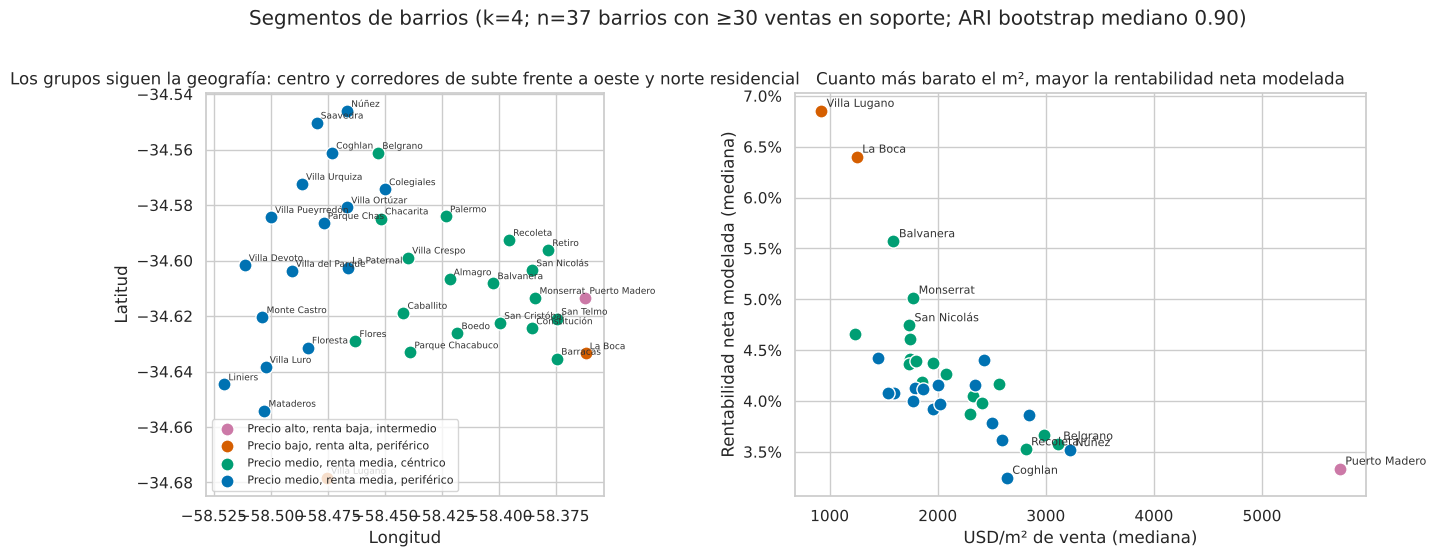

**Interpretación.** Con k=4 (mejor silhouette, 0.38) los barrios se separan, ante todo, por **centralidad** (delitos registrados y distancia al subte) y por **precio de entrada**. La rentabilidad neta mediana varía poco entre los grupos grandes (4.3%, 4.0%): la segmentación describe el tipo de entorno que compra el inversor más que su retorno. La partición es estable (ARI mediano 0.90, P5 0.68): en la mayoría de las réplicas se repite igual. Los grupos chicos (La Boca, Puerto Madero, Villa Lugano) son casos extremos de precio y rentabilidad, no perfiles de mercado. Utilidad: el segmento orienta dónde buscar según la tolerancia al entorno céntrico, pero la dispersión entre avisos de un mismo segmento es mayor que entre segmentos, así que no reemplaza a la priorización por aviso.

In [30]:
perfil = X_bar.assign(Grupo=etiquetas).groupby('Grupo').median()
perfil['USD_m2_venta'] = np.exp(perfil.pop('log_m2_venta'))
perfil['Delitos_1000m'] = np.expm1(perfil.pop('log_delitos'))
perfil['Dist_subte_m'] = np.expm1(perfil.pop('log_subte'))
perfil['Verde_1000m_m2'] = np.expm1(perfil.pop('log_verde'))
perfil['Barrios'] = etiquetas.value_counts().sort_index()
# Nombre de cada grupo según su perfil estandarizado (centro del grupo en desvíos respecto de la media de barrios),
# para que la etiqueta describa al grupo y no dependa del número que asigna k-means.
centros = pd.DataFrame(Z, index=X_bar.index, columns=list(VARS_SEG)).groupby(etiquetas).mean()
def nombrar(g):
    c = centros.loc[g]
    nivel = lambda z, alto, bajo, medio: alto if z > .5 else (bajo if z < -.5 else medio)
    partes = [nivel(c.log_m2_venta, 'precio alto', 'precio bajo', 'precio medio'),
              nivel(c.Rent_neta_modelo, 'renta alta', 'renta baja', 'renta media'),
              nivel(-c.log_subte, 'céntrico', 'periférico', 'intermedio')]
    return ', '.join(partes).capitalize()
nombres = {g: nombrar(g) for g in perfil.index}
repetidos = pd.Series(nombres).duplicated(keep=False)
nombres = {g: f'{n} ({g + 1})' if repetidos[g] else n for g, n in nombres.items()}
display(centros.rename(index=nombres, columns=VARS_SEG).round(2))
perfil.index = perfil.index.map(nombres)
barrios['Segmento'] = etiquetas.map(nombres)
display(perfil[['Barrios', 'USD_m2_venta', 'Rent_neta_modelo', 'Delitos_1000m', 'Dist_subte_m', 'Verde_1000m_m2']].round(3))
for nombre in perfil.index:
    print(f'{nombre}: {", ".join(sorted(barrios.index[barrios.Segmento.eq(nombre)]))}')

COLORES_SEG = dict(zip(perfil.sort_values('USD_m2_venta').index, ['#D55E00', '#009E73', '#0072B2', '#CC79A7', '#E69F00', '#56B4E9']))
fig, axs = plt.subplots(1, 2, figsize=(14, 5.5))
seg_plot = barrios.dropna(subset=['Segmento'])
for nombre, g in seg_plot.groupby('Segmento'):
    axs[0].scatter(g.Longitud, g.Latitud, s=90, color=COLORES_SEG[nombre], edgecolor='white', linewidth=1, label=nombre)
    axs[1].scatter(g.USD_m2_venta_mediana, g.Rent_neta_modelo, s=90, color=COLORES_SEG[nombre], edgecolor='white', linewidth=1, label=nombre)
# En el panel derecho solo se etiquetan los extremos de cada eje, para que los nombres no se superpongan.
extremos = set(seg_plot.Rent_neta_modelo.nlargest(5).index) | set(seg_plot.Rent_neta_modelo.nsmallest(4).index)     | set(seg_plot.USD_m2_venta_mediana.nlargest(3).index)
for b, r in seg_plot.iterrows():
    axs[0].annotate(b, (r.Longitud, r.Latitud), fontsize=6.5, xytext=(3, 3), textcoords='offset points', color='#333333')
    if b in extremos:
        axs[1].annotate(b, (r.USD_m2_venta_mediana, r.Rent_neta_modelo), fontsize=8, xytext=(4, 3), textcoords='offset points', color='#333333')
axs[0].set(xlabel='Longitud', ylabel='Latitud', title='Los grupos siguen la geografía: centro y corredores de subte frente a oeste y norte residencial')
axs[0].set_aspect(1 / np.cos(np.radians(-34.6)))
axs[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.1%}'))
axs[1].set(xlabel='USD/m² de venta (mediana)', ylabel='Rentabilidad neta modelada (mediana)',
           title='Cuanto más barato el m², mayor la rentabilidad neta modelada')
axs[0].legend(loc='lower left', fontsize=8)
fig.suptitle(f'Segmentos de barrios (k={K}; n={len(X_bar)} barrios con ≥30 ventas en soporte; ARI bootstrap mediano {np.median(ari):.2f})', y=1.01)
plt.tight_layout(); plt.show()
chico = perfil.Barrios.min()
lectura(f'Con k={K} (mejor silhouette, {siluetas[K]:.2f}) los barrios se separan, ante todo, por **centralidad** '
        '(delitos registrados y distancia al subte) y por **precio de entrada**. La rentabilidad neta mediana varía '
        f'poco entre los grupos grandes ({", ".join(f"{v:.1%}" for v in perfil.loc[perfil.Barrios.ge(5), "Rent_neta_modelo"])}): '
        'la segmentación describe el tipo de entorno que compra el inversor más que su retorno. '
        f'La partición es estable (ARI mediano {np.median(ari):.2f}, P5 {np.percentile(ari, 5):.2f}): en la mayoría de las réplicas '
        'se repite igual. ' + (f'Los grupos chicos ({", ".join(barrios.index[barrios.Segmento.isin(perfil.index[perfil.Barrios.le(2)])])}) '
        'son casos extremos de precio y rentabilidad, no perfiles de mercado. ' if chico <= 2 else '') +
        'Utilidad: el segmento orienta dónde buscar según la tolerancia al entorno céntrico, pero la dispersión entre avisos '
        'de un mismo segmento es mayor que entre segmentos, así que no reemplaza a la priorización por aviso.')

## 12. Estado de las hipótesis

Los p-valores unilaterales de los 11 contrastes se ajustan con **Holm**. El estado combina significancia ajustada, dirección y robustez:

- **Sostenida:** p ajustado < 0,05, en la dirección esperada y con el signo esperado en todas las especificaciones.
- **Sostenida con reservas:** p ajustado < 0,05 en la dirección esperada, pero el signo cambia en alguna especificación, o significativa sin ajustar y robusta.
- **Contraria a lo esperado:** el efecto es significativo (bilateral) en la dirección opuesta.
- **No sostenida:** no hay evidencia suficiente en la dirección esperada. No prueba que el efecto no exista.

In [31]:
resumen = pd.DataFrame(RESULTADOS)
resumen['p_Holm'] = multipletests(resumen.p_unilateral, method='holm')[1]
robusta = resumen['Robustez (signo esperado)'].map(lambda s: s.split('/')[0] == s.split('/')[1])

def estado(fila, robusta):
    if fila.p_Holm < ALFA and fila.Signo_esperado:
        return 'Sostenida' if robusta else 'Sostenida con reservas'
    if fila.p_unilateral < ALFA and fila.Signo_esperado and robusta:
        return 'Sostenida con reservas'
    if not fila.Signo_esperado and 1 - fila.p_unilateral < ALFA / 2:
        return 'Contraria a lo esperado'
    return 'No sostenida'

resumen['Estado'] = [estado(f, r) for (_, f), r in zip(resumen.iterrows(), robusta)]
pd.set_option('display.max_colwidth', 80)
display(resumen[['Hipótesis', 'Contraste', 'Estimación', 'IC95', 'p_unilateral', 'p_Holm', 'Magnitud',
                 'Robustez (signo esperado)', 'Estado']].set_index('Hipótesis'))

,Contraste,Estimación,IC95,p_unilateral,p_Holm,Magnitud,Robustez (signo esperado),Estado
Hipótesis,,,,,,,,
H1,Rentabilidad bruta Sur/Oeste > Norte premium (misma tipología),+20.6%,"[+7.8%, +40.6%]",0.0010,0.0110,+1.03 p.p. sobre una base de 5.01%,5/5,Sostenida
H3,Rentabilidad bruta 1–2 amb > 3+ amb (mismo barrio y tipo),-0.6%,"[-8.8%, +10.0%]",0.7165,1.0000,-0.03 p.p. sobre la mediana de 5.81%,0/4,No sostenida
H2a,Prima de la cochera mayor en venta que en alquiler,-0.030,"[-0.076, +0.016]",0.8989,1.0000,+3.0% en la rentabilidad bruta de la unidad,0/5,No sostenida
H2b,Prima de los amenities mayor en venta que en alquiler,+0.001,"[-0.013, +0.016]",0.4161,1.0000,-0.1% en la rentabilidad bruta de la unidad,4/5,No sostenida
H4,Distancia al subte → USD/m² de venta (−),-0.0093,"[-0.0262, +0.0076]",0.1363,1.0000,"-1.5% de P25 a P75 (-2,147 USD)",5/6,No sostenida
H4.5,Estaciones de subte a 500 m → USD/m² de venta (+),-0.0071,"[-0.0244, +0.0101]",0.7957,1.0000,"-0.7% de P25 a P75 (-1,033 USD)",0/6,No sostenida
H4b,Paradas de colectivo a 500 m → USD/m² de venta (bilateral),-0.0640,"[-0.1050, -0.0230]",0.0029,0.0292,"-4.3% de P25 a P75 (-6,306 USD)",6/6,Sostenida
H5,Delitos a 1.000 m → USD/m² de venta (−),+0.0045,"[-0.0389, +0.0480]",0.5828,1.0000,+0.4% de P25 a P75 (+608 USD),3/6,No sostenida
H8,Distancia al hospital → USD/m² de venta (−),-0.0142,"[-0.0451, +0.0167]",0.1805,1.0000,"-1.1% de P25 a P75 (-1,667 USD)",5/6,No sostenida


## 13. Exportación de indicadores

Se escriben cuatro archivos en `data/processed/`, que son la **fuente única del dashboard**: así el dashboard no recalcula nada y sus números coinciden con este notebook. El dataset de entrada no se modifica (se verifica con su hash al final).

In [32]:
COLS_AVISOS = ['Item_ID', 'Link', 'Barrio_Normalizado', 'Tipo_Propiedad', 'Ambientes', 'Ambientes_Agrupado',
               'Superficie_Total_m2', 'Antiguedad_limpia', 'Tipo_Vendedor', 'Latitud', 'Longitud', 'Precio_USD',
               'Expensas_Validas_USD', 'Flag_Expensas_Imputada', 'Precio_Estimado_USD', 'Precio_Estimado_Inf_USD',
               'Precio_Estimado_Sup_USD', 'Indice_Subvaluacion_Modelo', 'Subvaluacion_Fuera_Intervalo',
               'Alquiler_Estimado_USD', 'En_Soporte_Alquiler', 'Rentabilidad_Bruta_Aviso', 'Rentabilidad_Neta_Aviso',
               'Rentabilidad_Neta_Optimista', 'Rentabilidad_Neta_Pesimista', 'TIR_10_Anios',
               'Factor_Confianza', 'Flag_Precio_m2_Muy_Bajo', 'En_Universo_Priorizacion', 'Revision_Manual',
               'Indice_Priorizacion', 'Orden_Revision', 'Cantidad_Delitos_1000m', 'Distancia_Subte_m', 'Superficie_Verde_1000m_m2']
salida_avisos = avisos[COLS_AVISOS].assign(Comuna=lambda d: d.Barrio_Normalizado.map(ind.BARRIO_A_COMUNA),
                                           Zona_H1=lambda d: ind.zona_h1(d.Barrio_Normalizado),
                                           Segmento_Barrio=lambda d: d.Barrio_Normalizado.map(barrios.Segmento))
exportes = {'indicadores_avisos.csv': salida_avisos,
            'indicadores_barrio.csv': barrios.reset_index(),
            'rentabilidad_segmentos.csv': segmentos,
            'resultados_hipotesis.csv': resumen.drop(columns='Signo_esperado')}
for nombre, tabla in exportes.items():
    tabla.round(6).to_csv(SALIDA / nombre, index=False)
    print(f'{nombre}: {len(tabla):,} filas × {tabla.shape[1]} columnas')

indicadores_avisos.csv: 45,825 filas × 38 columnas
indicadores_barrio.csv: 48 filas × 24 columnas
rentabilidad_segmentos.csv: 129 filas × 16 columnas
resultados_hipotesis.csv: 11 filas × 11 columnas


## 14. Conclusiones, limitaciones y próximos pasos

### Conclusiones

1. **La zona importa para la rentabilidad (H1 sostenida, con un matiz).** Comparando la misma tipología, los segmentos del sur y oeste rinden alrededor de un 21% más que los del norte premium en términos relativos: cerca de +1 punto porcentual sobre una base de 5,0% anual (IC95% +8% a +41%, p de Holm 0,011, mismo signo en las 5 especificaciones). El matiz: con la definición estricta de la propuesta (Flores, Parque Avellaneda y Mataderos frente a Palermo, Recoleta y Belgrano) la diferencia se reduce y deja de ser significativa. El sur no es homogéneo: La Boca, Villa Lugano y Barracas rinden mucho, mientras que Mataderos y Liniers rinden como el norte.
2. **El tamaño de la unidad no cambia la rentabilidad (H3 no sostenida).** Dentro de un mismo barrio y tipo, las unidades de 1–2 ambientes rinden prácticamente igual que las de 3 o más (diferencia mediana −0,6%; en la mitad de los pares gana cada lado).
3. **Cochera y amenities no reducen la rentabilidad (H2 no sostenida).** La cochera eleva el USD/m² en 14% en venta y en 18% en alquiler; cada amenity de edificio, en 6,5% y 6,3%. La prima no es mayor en venta, que era lo que H2 esperaba: si hay alguna diferencia, va en el sentido contrario.
4. **Dentro de un barrio, el entorno inmediato pesa poco en el precio de venta.** Distancia al subte (H4), estaciones a 500 m (H4.5), delitos (H5) y distancia al hospital (H8) no muestran asociaciones distinguibles de cero cuando la incertidumbre se mide reconociendo que los avisos de un mismo barrio no son independientes. Esto corrige la lectura del notebook 04, cuyos errores HC3 eran demasiado optimistas para delitos. La única asociación robusta es la de los **colectivos (H4b)**: más paradas a 500 m se asocian con un USD/m² 4,3% menor (de P25 a P75, unos USD 6.300 sobre la venta mediana; 6 de 6 especificaciones; p de Holm 0,029), compatible con la penalización de vivir sobre avenidas de alto tránsito.
5. **El verde se valora, pero no de forma diferencial en unidades familiares (H7 reformulada, no sostenida).** Sin los establecimientos educativos, la componente escolar de H7 no pudo evaluarse.
6. **Particulares: evidencia sugestiva, no concluyente (H6).** Comparando dentro del mismo barrio, tipo y ambientes, los avisos de particulares tienen 4,3 p.p. más de probabilidad de quedar 15% o más por debajo de su precio estimado (p sin ajustar 0,011, consistente con los otros umbrales y con el índice continuo). Pero no supera la corrección de Holm, no aparece con el índice original y los particulares también aparecen más sobrevaluados: publican con más dispersión, no simplemente más barato.
7. **El modelo de precio supera claramente a la regla de comparables.** Fuera de muestra, el gradient boosting baja el error mediano de 16,9% a 9,7% en venta y de 17,0% a 12,1% en alquiler, de forma estable en los 5 pliegues. Reemplaza al `Indice_Subvaluacion` original, que se comparaba contra un grupo que incluía al propio aviso. Su intervalo del 90% cumple la cobertura prometida pero es ancho: sirve para priorizar avisos, no para tasarlos.
8. **Los costos bajan la rentabilidad, pero no cambian el orden.** Con vacancia, comisiones, expensas a cargo del dueño, mantenimiento, ABL y costos de compra, la rentabilidad mediana pasa de 6,3% bruta a 4,0% neta en el escenario base (entre 2,7% y 5,0% según el escenario). La TIR a 10 años, con costos de compra y de venta y sin valorización, es de 2,9%. El sur/oeste sigue rindiendo más que el norte premium en los tres escenarios. La definición anterior restaba las expensas ordinarias completas, que en un alquiler paga el inquilino, y omitía el resto de los costos.
9. **La rentabilidad por aviso y el índice de priorización sirven para ordenar qué revisar, no para decidir la compra.** La rentabilidad modelada reproduce el orden de la observada (Spearman 0,70, con un sesgo de nivel de +11%). Mover ±25 puntos el peso entre rentabilidad y subvaluación conserva entre el 81% y el 83% del top 100, y cambiar los supuestos de costos conserva el 98–99%. La elección entre "más renta" y "más descuento" sí cambia la lista, y apartar los precios/m² muy bajos es la decisión de mayor impacto. No hay datos de resultados posteriores para validar la regla como criterio de inversión: por eso se presenta como herramienta de screening.

### Implicancias para la búsqueda (screening, no recomendación de inversión)

Los resultados ordenan dónde mirar primero. No reemplazan la evaluación de cada inmueble ni constituyen una recomendación de compra. Se apoyan en precios publicados, el dólar del día del scraping, alquiler tradicional y los supuestos de costos del escenario base.

- **Dónde mirar primero:** los barrios de precio de entrada bajo o medio con rentabilidad neta modelada alta. En el escenario base son Villa Lugano (6,9%), La Boca (6,4%), Balvanera (5,6%), Monserrat (5,0%), San Nicolás, Constitución y San Cristóbal (entre 4,6% y 4,7%). El norte premium rinde menos por cada dólar invertido (Belgrano, Recoleta y Núñez, alrededor de 3,5%). Su atractivo, si existe, es otro, como liquidez o valorización, y este análisis no lo mide.
- **Qué mirar en la unidad:** el tamaño no cambia la rentabilidad relativa. Conviene elegirlo según el presupuesto y la facilidad de reventa.
- **Cómo usar el índice de priorización:** como una **lista corta de avisos a verificar**, empezando por los que están fuera del intervalo de precio del modelo. Un descuento grande frente a la referencia puede ser una oportunidad, pero también un error de carga o un mal estado del inmueble que el aviso no informa.
- **Particulares:** sus avisos merecen revisión porque su precio es más disperso, en ambas direcciones.

### Limitaciones

- **Alquileres escasos y de modalidad incierta:** 4.099 alquileres frente a 45.825 ventas. El 94% de los alquileres no declara modalidad. Los temporarios declarados están 2,4 veces sobrerrepresentados en el centro (Balvanera, Monserrat, San Nicolás, San Cristóbal, Constitución y Retiro), así que parte de la rentabilidad alta de esos barrios podría venir de temporarios no declarados.
- **Precios publicados, no de cierre**, en una foto de cuatro días de agosto de 2026, convertidos con el dólar blue del día. La sensibilidad cambiaria ya se cuantificó en el notebook 04.
- **Rentabilidad por aviso:** es la estimación de un modelo de alquiler aplicada a unidades en venta. El 27% de las ventas está fuera del soporte de los alquileres y no entra en la priorización. Los costos son supuestos con escenarios: el ABL y las expensas extraordinarias no tienen una fuente por aviso, y la liquidez solo entra por los costos de salida, porque el dataset no tiene tiempos de venta.
- **Inferencia:** H1 se apoya en 15 barrios con alquileres suficientes. Los errores agrupados por barrio no capturan la dependencia espacial entre barrios vecinos. Los duplicados no detectados pueden filtrarse entre pliegues de la validación cruzada.
- **Medición del entorno:** distancias en línea recta, ubicaciones aproximadas y delitos como conteo acumulado a 1.000 m, no como tasa por habitante.
- Todo lo anterior son **asociaciones**: ningún coeficiente identifica un efecto causal.

### Próximos pasos

1. **Dashboard** para el interlocutor, alimentado exclusivamente por los cuatro CSV exportados en la sección 13: mapa y tabla de barrios, lista de avisos a revisar filtrable por presupuesto, tipo y ambientes, ficha de cada aviso con su intervalo de precio, y sensibilidad del índice a los pesos y a los costos.
2. Auditar manualmente los primeros 100 avisos de la lista contra las publicaciones originales.
3. Clasificar los alquileres temporarios a partir del texto del aviso, para depurar la rentabilidad de los barrios céntricos.
4. Integrar los establecimientos educativos para evaluar H7 completa.
5. Repetir el scraping para construir un panel: tiempo de publicación como medida de liquidez y validación temporal del modelo.

In [33]:
assert sha256(RUTA) == HASH_ENTRADA, 'El dataset de entrada cambió durante la ejecución.'
print('OK: dataset de entrada sin modificaciones.')
print('Versiones:', {p: metadata.version(p) for p in ['pandas', 'numpy', 'scipy', 'statsmodels', 'scikit-learn', 'matplotlib', 'seaborn']})
print('Python:', sys.version.split()[0])

OK: dataset de entrada sin modificaciones.
Versiones: {'pandas': '3.0.5', 'numpy': '2.5.3', 'scipy': '1.18.1', 'statsmodels': '0.15.0', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2', 'seaborn': '0.13.2'}
Python: 3.13.17
